# PP1 — Complexity-Stratified XAI Evaluation (Function 2)

**Stage: F2.6-QA (final, research-consolidation + independent audit).**
This is the complete, final PP1 notebook for Component 1 / Function 2: it
covers the full pipeline end to end — background-complexity feature
definition and calibration (F2.1), VALID ground-truth and reference-mask
audits (F2.2), Grad-CAM / Grad-CAM++ generation (F2.3), localization /
faithfulness / stability / sanity-check / execution-time evaluation (F2.4),
complexity-stratified analysis and weighting-sensitivity amendment (F2.5 /
F2.5-S1), and the F2.6 final findings, threats to validity, and F2.7 handoff.
Every number in Sections 4 onward is loaded live from real result files, not
hand-typed or placeholder. This v2 notebook is the output of an independent
F2.6-QA audit pass over the F2.6 v1 notebook
(`pp1_xai_evaluation_final_v1.ipynb`, preserved unmodified): it corrects
stale `Not Implemented Yet` section headers left over from earlier
single-stage drafts, repositions one out-of-order section, fixes a
metric-wording inaccuracy in the Pointing Accuracy description (the
underlying numbers were independently verified as correct — see
`f26_qa_v1/reports/f26_pointing_metric_definition_audit.md`), and adds
nbformat-4.5 cell IDs. Every intentional change from v1 is listed in
`f26_qa_v1/reports/f26_notebook_v1_to_v2_changes.md`. No result, number,
figure, or provenance record was altered.

## Section 1 — Research Problem Statement

### 1.1 Context: what is frozen today

Component 1, Function 1 (defect detection) is **frozen and operational**:

- **Model**: `E02_optimized`, a YOLOv8n detector fine-tuned on the Chenab 7-class fabric-defect dataset (`baekra, color issues, contamination, cut, gray stitch, selvet, stain`). Selected over two rejected candidates (E01, E03) on validation mAP50-95 (0.4205 vs 0.3757 / 0.3071), with consistent wins on precision, recall, and every per-class AP50. Frozen checkpoint: `runs/component1_training/E02_optimized/weights/best.pt`, SHA-256-verified against `runs/component1_training/freeze/model_freeze_E02_optimized_v1.json` as part of this stage's Task 1 (see `../reports/task1_input_verification.md`).
- **Explainability**: `research/component1/xai_experiments/src/detection_xai.py` implements genuine **Grad-CAM** and **Grad-CAM++** for this detector. Both methods backpropagate from the *raw class logit* (pre-sigmoid) of a verified, NMS-surviving detection, through one of three candidate feature layers (P3/P4/P5, strides 8/16/32), and differ only in how per-channel CAM weights are computed:
  - **Grad-CAM**: weight = spatial mean of the gradient at that layer.
  - **Grad-CAM++**: weight = an $\alpha$-weighted ReLU(gradient) term that accounts for higher-order gradient interactions, intended to localise better when multiple instances of the same class appear in one image.
  - Both are verified against the *same* forward pass used for detection (re-run with autograd enabled, then the target detection's identity is re-confirmed by matching class id and confidence within `1e-4` before backpropagating), so the explanation is guaranteed to correspond to the actual surviving detection, not a stale or mismatched one.

### 1.2 The research problem this Function addresses

Grad-CAM-family heatmaps are visually persuasive but are known in the broader XAI literature to vary in **reliability** depending on the input image's own visual characteristics — notably, textured/high-frequency backgrounds can produce noisier or less-localised saliency than plain backgrounds, independent of whether the detector's prediction itself is correct. For a fabric-inspection system, this matters directly: inspectors need to trust the heatmap specifically on **complex-weave, patterned, or high-contrast fabrics**, not just on plain cotton.

**Function 2's research question**: *does the quality of Grad-CAM / Grad-CAM++ explanations for the frozen E02 detector depend on the visual complexity of the fabric background, and if so, how much and in what way?*

This motivates a **complexity-stratified evaluation design**: group evaluation images into Simple / Moderate / High background-complexity strata (thresholds *not yet calibrated* — see Section 2.4), then compare XAI quality metrics across strata rather than only reporting one pooled number.

### 1.3 Expected evaluation outputs (PP1 scope, not yet implemented)

Per `research/component1/README.md`'s PP1 scope, the eventual (not-yet-built) evaluation will report, per stratum and pooled:

1. **Localization** — agreement between the Grad-CAM/Grad-CAM++ heatmap's high-activation region and the detector's own ground-truth-verified bounding box (e.g. pointing-game or IoU-style overlap metrics).
2. **Faithfulness** — whether deleting/inserting the heatmap's highest-attributed pixels changes the model's output score in the expected direction (deletion/insertion-style curves).
3. **Stability** — whether small, label-preserving input perturbations (e.g. minor noise, slight shifts) produce consistent heatmaps.
4. **Sanity checks** — e.g. a model-randomisation test: does the heatmap degrade toward noise when model weights are randomised, as it should if the heatmap is genuinely explaining the trained model rather than just edge-detecting the input?
5. **Execution time** — wall-clock cost per explanation, per method, since this feeds the practical deployment decision between Grad-CAM and Grad-CAM++.

### 1.4 What this final notebook covers, and what remains out of scope

This notebook now covers the full PP1 pipeline through F2.6: the frozen
model/dataset and background-complexity descriptors (Sections 2-3F), Grad-CAM
/ Grad-CAM++ generation (Section 4), the full localization / faithfulness /
stability / sanity-check / execution-time metric suite (Sections 5-9),
complexity-stratified analysis, confounding, selection-bias, and
weighting-sensitivity results (Sections 10-14), and the final findings,
threats to validity, and F2.7 handoff (Sections 15-17). Every metric named in
Section 1.3 has been computed and is reported with its real value, sample
size, and (where applicable) family-level bootstrap CI -- none is a
placeholder. What remains explicitly out of scope for this package: any
expert/QC validation of the complexity protocol, any causal claim about a
complexity effect, any F2.4-C pixel-IoU expansion beyond the existing 29-mask
pilot, and all F2.7 (slide/deck) production work (see Section 17).

## Section 2 — Real Function 2 Modules, Sample Measurements

This section imports the **real** Function 2 F2.1A modules (no reimplemented math) and the **real, unmodified** shared `complexity_features` module, then displays genuine sample images and their extracted measurements from the Task 5 smoke test (`../results/calibration/smoke_test_features.csv` — 20 deterministic TRAIN-split images; see `../reports/`).

> **Execution note (honesty disclosure):** this environment has no Jupyter kernel / `nbformat`/`ipykernel` installed, so this notebook's code cells were not run live inside a kernel. The code below was instead executed exactly as written via a plain Python process (`backend/.venv`, which does have `cv2`/`numpy`/`matplotlib`/`pillow`), against the real files in this repository, and its genuine stdout and a genuine rendered PNG figure are embedded as this cell's outputs below. Nothing in the output was hand-written or estimated.


All 20 sampled images re-confirmed as split='train' via the authoritative manifest.
chenab_test_00004488_jpg.rf.207e06d40a9bf92c322c7e68109ce3b3 | defects: ["gray stitch"] | status: ok
chenab_test_20230712_141336_jpeg_jpg.rf.67998702da1d47f1147519b8bbb419a4 | defects: ["cut"] | status: error_insufficient_fabric
chenab_test_20230712_160021_jpeg_jpg.rf.702988720873053b0a893ac739556910 | defects: [] | status: ok


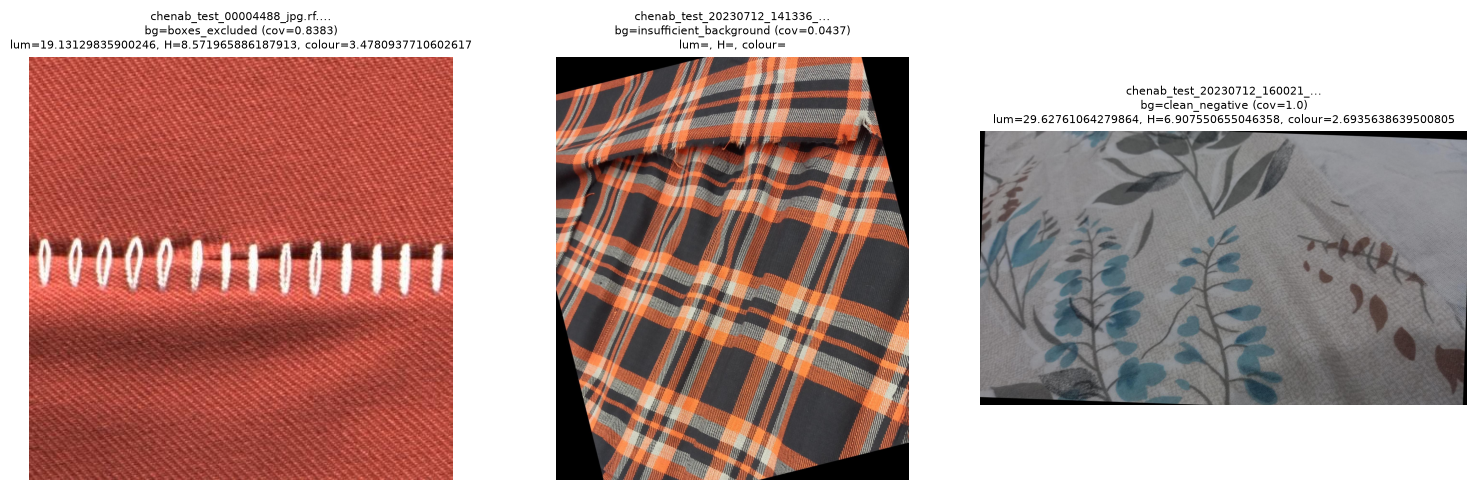

In [1]:
import csv
import sys
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    """Walk upward from `start` until a directory containing `.git` is
    found. Robust to being launched via `jupyter notebook` from the
    notebooks/ directory itself (where the kernel's CWD is notebooks/,
    not the repo root), not just as a plain script with a known fixed
    relative depth."""
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate
    raise RuntimeError(f"Could not locate repo root (no .git found) walking up from {start}")

REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT))

import cv2
import matplotlib.pyplot as plt

# Real, unmodified shared module (not reimplemented):
from research.component1.complexity_calibration.src.complexity_features import DEFAULT_CONFIG

# Real Function 2 F2.1A modules:
from research.component1.function2.complexity.background_region import compute_background_mask
from research.component1.function2.dataset.manifest_loader import build_split_lookup, assert_train_split

CSV_PATH = REPO_ROOT / "research/component1/function2/results/calibration/smoke_test_features.csv"
with open(CSV_PATH, newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

# Hard safety check before displaying anything: re-confirm every sampled
# image is actually train-split, from the authoritative manifest.
split_lookup = build_split_lookup()
for row in rows:
    assert_train_split(row["image_id"], split_lookup)
print(f"All {len(rows)} sampled images re-confirmed as split='train' via the authoritative manifest.")

# Show one real example per background-selection outcome actually observed.
wanted_statuses = ["boxes_excluded", "insufficient_background", "clean_negative"]
examples, seen = [], set()
for row in rows:
    if row["background_method"] in wanted_statuses and row["background_method"] not in seen:
        examples.append(row); seen.add(row["background_method"])

fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5))
for ax, row in zip(axes, examples):
    img_rgb = cv2.cvtColor(cv2.imread(str(REPO_ROOT / row["relative_path"])), cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb); ax.axis("off")
    ax.set_title(f"{row['image_id'][:28]}...\nbg={row['background_method']} (cov={row['background_coverage_fraction']})\n"
                 f"lum={row['luminance_variation']}, H={row['glcm_entropy']}, colour={row['colour_variation']}", fontsize=8)
    print(row["image_id"], "| defects:", row["defect_class_names"], "| status:", row["processing_status"])
plt.tight_layout(); plt.show()


### 2.1 Why these three descriptors

The shared `complexity_features.py` module measures three provisional (its own `protocol_version="proto_v0.1_provisional"`) background-texture descriptors, chosen because each targets a different, largely independent axis of "visual busyness" that could plausibly confound a saliency heatmap:

1. **Luminance variation** (`σ(L*)` in CIE L*a*b*) — captures brightness non-uniformity (shading, weave shadowing, sheen) independent of colour. A Grad-CAM heatmap riding on raw activation magnitude can be sensitive to local brightness swings unrelated to the defect.
2. **GLCM entropy** — a classical second-order texture statistic capturing *spatial* randomness of the gray-level pattern (fine weave texture, print patterns), which luminance/colour variation (first-order, pixel-independent statistics) cannot capture on their own.
3. **Lab colour variation** (`mean(σ(a*), σ(b*))`) — captures chromatic patterning (printed/dyed fabrics) separately from luminance and spatial texture.

Together they span *brightness*, *spatial texture*, and *colour* — three qualitatively different ways a background can be "complex" — without yet asserting that any one of them, or any combination, actually predicts XAI quality. That causal question is exactly what the (not yet implemented) F2.1B/PP1 evaluation exists to answer.

### 2.2 Full verified math, assumptions, and edge cases

See `../reports/task3_complexity_feature_verification.md` for the complete, test-backed specification (BGR2LAB assumptions, GLCM quantisation/angles/pooling, resize behaviour, flat-image behaviour, dtype/NaN guarantees, and — critically — a verified inconsistency in how `compute_complexity_from_array`'s GLCM entropy does **not** respect a background mask, unlike its luminance/colour outputs).

### 2.3 Background-region selection

See `../reports/task4_background_region_strategy.md`. In short: ground-truth YOLO boxes are rasterised and excluded from the measurement region as a documented **approximation** (not a pixel-accurate segmentation), with an explicit `insufficient_background` status when GT boxes cover too much of the image, and annotation-missing images are treated as **unresolved**, never silently assumed clean.

### 2.4 Complexity thresholds — explicitly NOT yet calibrated

**No Simple / Moderate / High complexity thresholds exist yet.** The three raw feature values shown above are measurements only. Any stratification boundary would need to be calibrated against a principled criterion decided independently of any XAI outcome (e.g. percentile bands over a much larger, representative sample of background-complexity measurements) — that calibration work is explicitly out of scope here and is the planned subject of a later, separately-approved F2.1B2 stage.

**Methodological validity requirement (explicit, load-bearing):** complexity groups (Simple/Moderate/High) must be established and FROZEN *before* any confirmatory Grad-CAM/Grad-CAM++ quality evaluation is run against them. Choosing or adjusting thresholds using downstream XAI-quality results (even informally, even after only glancing at preliminary numbers) would make the evaluation circular — it would no longer be a test of whether complexity predicts XAI quality, it would be a description of whatever grouping happened to produce the result someone was looking for. This notebook and this stage (F2.1B1) do not run any Grad-CAM/XAI experiment, specifically so that no such contamination can happen even by accident.


### 2.5 F2.1B1 correction: mask-aware GLCM entropy

**This is why this correction stage (F2.1B1) exists.** F2.1A's own
verification work (`../reports/task3_complexity_feature_verification.md`
section 4) found, empirically (not just by reading the source), that the
shared module's array-based entry point,
`complexity_features.compute_complexity_from_array` -- the one this
package's smoke test uses -- applies the background-exclusion mask to
`luminance_variation` and `colour_variation` correctly (via boolean pixel
indexing), but **does not apply the mask to `glcm_entropy` at all**: the
GLCM is always computed over the *whole* image, defect pixels included.
Concretely, F2.1A measured `glcm_entropy` as bit-identical
(`11.200488668929722`) for two different masks (full image vs. left-half
excluded) over the same image, while `luminance_variation` changed as
expected -- proof the mask was silently ignored for that one feature. The
shared module's OTHER public entry point, the file-based
`compute_complexity()`, takes a different but also unsatisfactory approach:
it zero-fills excluded pixels before running the GLCM, which creates a
large number of fake (real-pixel, 0) co-occurrence pairs along every mask
boundary -- an artefact of mask geometry, not fabric texture.

Neither existing behaviour correctly measures "background GLCM entropy".
This stage (F2.1B1) adds two NEW modules under
`research/component1/function2/complexity/` -- `masked_glcm.py` and
`background_features.py` -- that fix this by construction: a GLCM
neighbour pair contributes to the co-occurrence matrix **only if both of
its pixels are inside the valid background mask**. No zero-filling, no
whole-image fallback. The shared `complexity_features.py` module itself is
**not modified** (it is frozen; other workflows depend on it) -- this is
new, additional code that sits alongside it and reuses its already-correct
luminance/colour-variation computation plus its quantisation/distance/
angle/pooling conventions (64 gray levels, distance 1, four angles pooled
into one matrix), while replacing only the mask-unaware GLCM step.

See `../reports/task5_smoke_test_v2_comparison.md` for the full before/after
comparison on the same 20 real images, and
`../complexity/masked_glcm.py` / `../complexity/background_features.py`
for the implementation and design-decision documentation (minimum-valid-
pairs threshold, resize-boundary-contamination finding and mitigation,
quality-flag semantics).


### 2.6 Genuine corrected measurements (F2.1B1 Task 5 re-run)

The cell below loads the REAL output of `dataset/smoke_test_extraction_v2.py` (`../results/calibration/smoke_test_features_v2_masked_glcm.csv` / `..._metadata_v2_masked_glcm.json`) -- the same 20 real images shown above, re-measured with the corrected mask-aware GLCM. **Execution note (honesty disclosure, same as Section 2's cell above):** no live Jupyter kernel / `nbformat`/`ipykernel` is available in this environment, so this cell's code was executed exactly as written via a plain Python process against the real repository files, and its genuine stdout and a genuine rendered PNG figure are embedded below. Nothing in the output was hand-written or estimated.

Loaded 20 rows from the F2.1B1 corrected (mask-aware GLCM) re-run.
Delta summary (v2 masked - v1 unmasked), from smoke_test_metadata_v2_masked_glcm.json :
{
  "n_comparable": 18,
  "mean_delta": -0.4320931773169614,
  "min_delta": -2.2563107576671726,
  "max_delta": 0.053687545815781945
}

Per-image comparison (old unmasked vs new masked GLCM entropy):
image_id                                    cov  v1_unmasked  v2_masked    delta        glcm_status
---------------------------------------------------------------------------------------------------
chenab_test_00004488_jpg.rf.207e06d40a    0.838       8.5720     8.1306  -0.4414              valid
chenab_test_00065510_jpg.rf.54b199584b    0.893       8.7804     8.6450  -0.1355              valid
chenab_test_006863_jpg.rf.da6ca0426389    0.818       8.6525     8.4772  -0.1754              valid
chenab_test_20230712_141336_jpeg_jpg.r    0.044          n/a     6.1959      n/a              valid
chenab_test_20230712_141549_jpeg_jpg.r    0.0

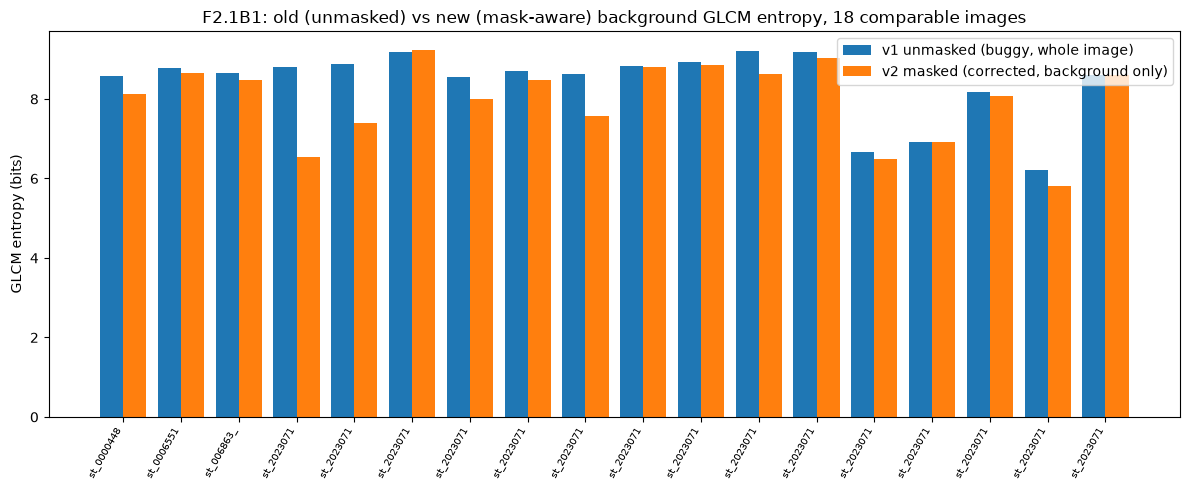

In [2]:
import csv
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

V2_CSV_PATH = REPO_ROOT / "research/component1/function2/results/calibration/smoke_test_features_v2_masked_glcm.csv"
V2_JSON_PATH = REPO_ROOT / "research/component1/function2/results/calibration/smoke_test_metadata_v2_masked_glcm.json"

with open(V2_CSV_PATH, newline="", encoding="utf-8") as f:
    v2_rows = list(csv.DictReader(f))
with open(V2_JSON_PATH, encoding="utf-8") as f:
    v2_meta = json.load(f)

print(f"Loaded {len(v2_rows)} rows from the F2.1B1 corrected (mask-aware GLCM) re-run.")
print("Delta summary (v2 masked - v1 unmasked), from", V2_JSON_PATH.name, ":")
print(json.dumps(v2_meta["glcm_entropy_delta_summary"], indent=2))

print("\nPer-image comparison (old unmasked vs new masked GLCM entropy):")
header = f"{'image_id':<40} {'cov':>6} {'v1_unmasked':>12} {'v2_masked':>10} {'delta':>8} {'glcm_status':>18}"
print(header)
print("-" * len(header))
for row in v2_rows:
    v1 = row["glcm_entropy_v1_unmasked"]
    v2 = row["glcm_entropy_v2_masked"]
    delta = row["glcm_entropy_delta"]
    v1_s = f"{float(v1):.4f}" if v1 not in ("", None) else "n/a"
    v2_s = f"{float(v2):.4f}" if v2 not in ("", None) else "n/a"
    d_s = f"{float(delta):+.4f}" if delta not in ("", None) else "n/a"
    print(f"{row['image_id'][:38]:<40} {float(row['background_coverage_fraction']):>6.3f} {v1_s:>12} {v2_s:>10} {d_s:>8} {row['glcm_status']:>18}")

# Bar chart: old vs new GLCM entropy per image (only rows where both exist).
comparable = [r for r in v2_rows if r["glcm_entropy_v1_unmasked"] not in ("", None) and r["glcm_entropy_v2_masked"] not in ("", None)]
labels = [r["image_id"][9:19] for r in comparable]
v1_vals = [float(r["glcm_entropy_v1_unmasked"]) for r in comparable]
v2_vals = [float(r["glcm_entropy_v2_masked"]) for r in comparable]

fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(comparable))
ax.bar([i - 0.2 for i in x], v1_vals, width=0.4, label="v1 unmasked (buggy, whole image)")
ax.bar([i + 0.2 for i in x], v2_vals, width=0.4, label="v2 masked (corrected, background only)")
ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
ax.set_ylabel("GLCM entropy (bits)")
ax.set_title("F2.1B1: old (unmasked) vs new (mask-aware) background GLCM entropy, 18 comparable images")
ax.legend()
plt.tight_layout()
plt.show()

print("\nFull per-image comparison with validity flags/reasons: ../reports/task5_smoke_test_v2_comparison.md")


### 2.7 Transition to F2.1B2 calibration

Sections 2.1–2.6 above cover F2.1A/F2.1B1 (feature definitions, the mask-aware GLCM
correction, and the 20-image smoke test). **Section 3 below is F2.1B2**: the larger
(near-full, 1,900-image) training-side extraction, distribution analysis, a candidate
composite score, and provisional (NOT frozen) Simple/Moderate/High thresholds. As
before, nothing here has been validated by Grad-CAM/XAI results, and none will be used
to adjust it.


## Section 3 — Background Complexity Calibration (F2.1B2)

**Stage F2.1B2: candidate calibration, explicitly NOT frozen, expert review pending.**

This section replaces the earlier "Not Implemented Yet" placeholder. It reports the
real output of the F2.1B2 pipeline: a unified eligibility policy
(`complexity/eligibility.py`), a near-full TRAIN-split extraction (1,900/1,900 images,
`dataset/train_extraction_v1.py`), a distribution analysis
(`dataset/distribution_analysis_v1.py`), a candidate composite score
(`complexity/scoring.py` + `dataset/calibration_scoring_v1.py`, config
`config/calibration_v1.json`), and candidate Simple/Moderate/High thresholds. Full
narrative detail and all numbers below are in `../reports/b2_task1_eligibility_policy.md`
through `b2_task7_expert_review_package.md`.

**Execution note (honesty disclosure, same as Section 2):** no live Jupyter kernel /
`nbformat`/`ipykernel` is available in this environment. Every code cell below was
executed exactly as written via a plain Python process (`backend/.venv`) against the
real repository files (the real 1,900-image CSV, the real JSON summaries, the real PNG
figures already produced by the F2.1B2 scripts), and its genuine stdout and genuine
rendered PNG figures are embedded as that cell's outputs. Nothing below was hand-written,
estimated, or fabricated.

### 3.1 Measurement equations (recap)

1. **Luminance variation**: $\sigma(L^*)$ — population std. dev. of the CIE L* channel
   (OpenCV 8-bit-scaled), over the valid background mask.
2. **GLCM entropy**: $H = -\sum_{i,j} p_{ij} \log_2 p_{ij}$, Shannon entropy of the
   (mask-aware, pair-exclusion) gray-level co-occurrence matrix, 64 levels, distance 1,
   4 angles pooled.
3. **Lab colour variation**: $\tfrac{1}{2}(\sigma(a^*) + \sigma(b^*))$ — mean std. dev.
   of the two CIE Lab chroma channels, same mask.

See Section 2.1/2.2 for the full verified specification and Section 2.5 for the
mask-aware GLCM correction this calibration relies on.

### 3.2 Eligibility policy and extraction coverage


In [21]:

import csv
import json
from pathlib import Path

CALIB_DIR = REPO_ROOT / "research/component1/function2/results/calibration"
CONFIG_PATH = REPO_ROOT / "research/component1/function2/config/calibration_v1.json"

with open(CALIB_DIR / "train_distribution_summary_v1.json", encoding="utf-8") as f:
    dist_summary = json.load(f)
with open(CALIB_DIR / "calibration_scoring_summary_v1.json", encoding="utf-8") as f:
    calib_summary = json.load(f)
with open(CONFIG_PATH, encoding="utf-8") as f:
    calib_config = json.load(f)

print(f"Eligibility: n_total={dist_summary['n_total_rows']}, n_eligible={dist_summary['n_eligible']}, "
      f"n_ineligible={dist_summary['n_ineligible']} ({dist_summary['eligible_fraction']:.1%} eligible)")
print("Rejection reasons:", dist_summary["rejection_reason_counts"])
print()
print("Per-feature summary stats (eligible, n=1747):")
for feat, stats in dist_summary["feature_summary_stats_eligible"].items():
    print(f"  {feat:22s} mean={stats['mean']:.3f} std={stats['std']:.3f} "
          f"median={stats['median']:.3f} min={stats['min']:.3f} max={stats['max']:.3f}")
print()
print("Pairwise Pearson correlations:")
for pair, r in dist_summary["pairwise_pearson_correlations_eligible_complete_rows"].items():
    print(f"  {pair}: r={r:.3f}")


Eligibility: n_total=1900, n_eligible=1747, n_ineligible=153 (91.9% eligible)
Rejection reasons: {'luminance_invalid_or_nonfinite': 37, 'background_coverage_insufficient_provisional_70pct_rule': 116}

Per-feature summary stats (eligible, n=1747):
  luminance_variation    mean=36.740 std=16.321 median=38.269 min=4.252 max=81.853
  glcm_entropy           mean=6.373 std=1.684 median=6.490 min=2.650 max=10.866
  colour_variation       mean=4.985 std=6.480 median=1.735 min=0.000 max=41.313

Pairwise Pearson correlations:
  luminance_variation__vs__glcm_entropy: r=0.349
  luminance_variation__vs__colour_variation: r=0.407
  glcm_entropy__vs__colour_variation: r=0.510


### 3.3 Feature distributions (real histograms, n=1,747 eligible)

Real histograms loaded from results/calibration/figures/hist_<feature>.png (Task 3 output).


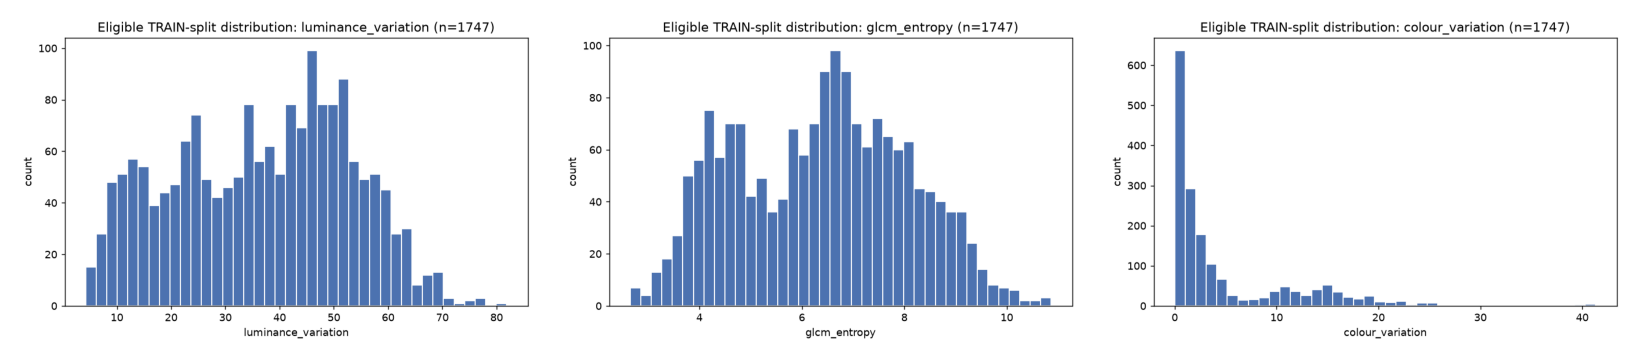

In [22]:

import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, feat in zip(axes, ["luminance_variation", "glcm_entropy", "colour_variation"]):
    img = mpimg.imread(CALIB_DIR / "figures" / f"hist_{feat}.png")
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()
print("Real histograms loaded from results/calibration/figures/hist_<feature>.png (Task 3 output).")


### 3.4 Pairwise correlations and source-family distribution

Source families: 684 distinct families in the full 1,900-image TRAIN split (656 with >=1 eligible image); size range [1, 12], mean 2.78.


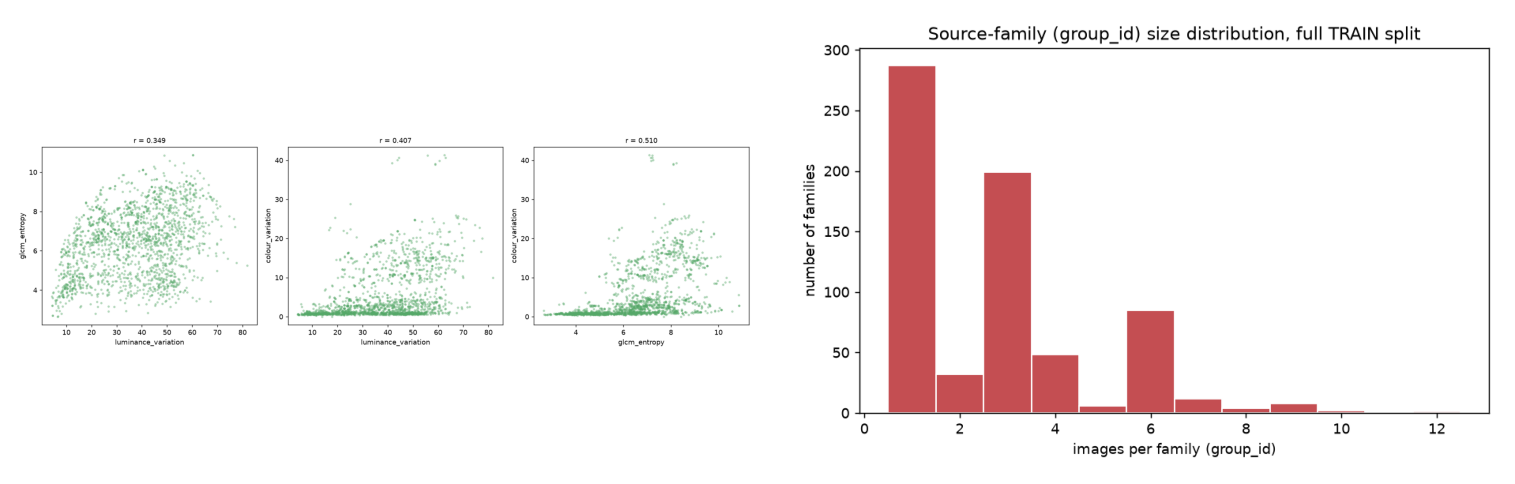

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
img1 = mpimg.imread(CALIB_DIR / "figures" / "pairwise_scatter.png")
axes[0].imshow(img1); axes[0].axis("off")
img2 = mpimg.imread(CALIB_DIR / "figures" / "family_size_distribution.png")
axes[1].imshow(img2); axes[1].axis("off")
plt.tight_layout(); plt.show()

fam = dist_summary["source_family_distribution"]
print(f"Source families: {fam['n_distinct_families_in_full_csv']} distinct families in the full "
      f"1,900-image TRAIN split ({fam['n_distinct_families_among_eligible']} with >=1 eligible image); "
      f"size range [{fam['family_size_min']}, {fam['family_size_max']}], mean {fam['family_size_mean']:.2f}.")


### 3.5 Confirmed-negative vs. box-excluded-defective comparison

luminance_variation: confirmed_negative mean=44.33 (n=154) vs box_excluded_defective mean=36.01 (n=1593)
glcm_entropy: confirmed_negative mean=7.81 (n=154) vs box_excluded_defective mean=6.23 (n=1593)
colour_variation: confirmed_negative mean=8.21 (n=154) vs box_excluded_defective mean=4.67 (n=1593)


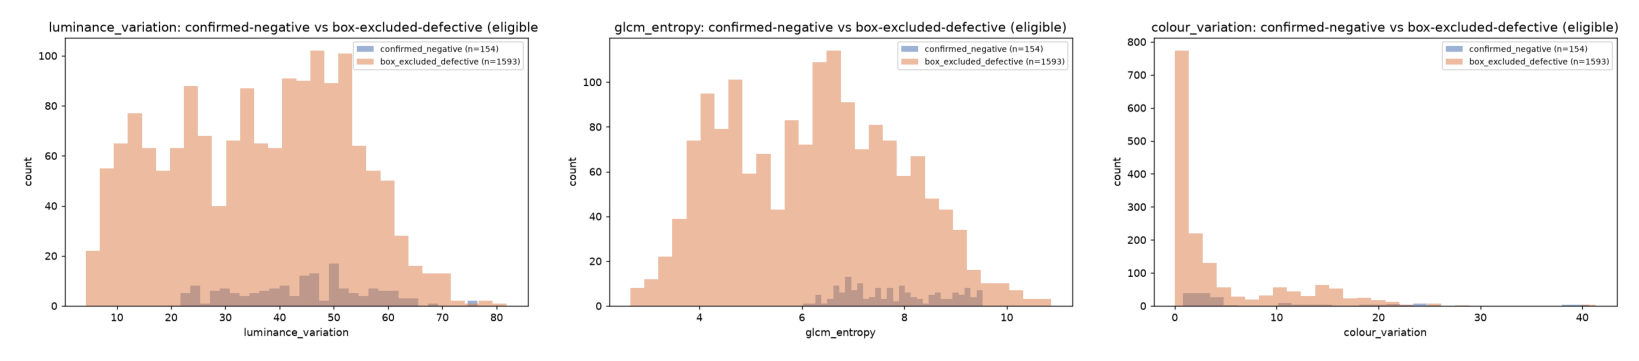

In [24]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, feat in zip(axes, ["luminance_variation", "glcm_entropy", "colour_variation"]):
    img = mpimg.imread(CALIB_DIR / "figures" / f"negative_vs_boxexcluded_{feat}.png")
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()

cmp = dist_summary["confirmed_negative_vs_box_excluded_comparison"]
for feat, d in cmp.items():
    neg, pos = d["confirmed_negative"], d["box_excluded_defective"]
    print(f"{feat}: confirmed_negative mean={neg['mean']:.2f} (n={d['n_confirmed_negative']}) vs "
          f"box_excluded_defective mean={pos['mean']:.2f} (n={d['n_box_excluded_defective']})")


### 3.6 Composite score: normalization and weighting (candidate, NOT validated)

z-score normalization using eligible-training-only mean/std; equal 1/3 weighting is the
documented default candidate, not a validated optimum. See
`../reports/b2_task5_composite_scoring.md` for the full weight-sensitivity discussion
(changing the weighting moves ~19–21% of images between groups) and the honest
assessment of whether one composite score is fully justified (moderate, not high,
pairwise feature correlations: r=0.35–0.51).

In [25]:

print("Normalization parameters (z-score, population mean/std over eligible TRAIN rows):")
for feat, params in calib_config["normalization"]["features"].items():
    print(f"  {feat:22s} mean={params['mean']:.4f} std={params['std']:.4f}")
print()
print("Weights (candidate, equal 1/3 each):", calib_config["weights"]["candidate"])
print("Weight label:", calib_config["weights"]["candidate_label"])
print()
print(f"Composite score = sum(w_f * z_f) over the 3 features. Status: {calib_config['status']}")


Normalization parameters (z-score, population mean/std over eligible TRAIN rows):
  luminance_variation    mean=36.7404 std=16.3211
  glcm_entropy           mean=6.3733 std=1.6843
  colour_variation       mean=4.9853 std=6.4799

Weights (candidate, equal 1/3 each): {'luminance_variation': 0.3333333333333333, 'glcm_entropy': 0.3333333333333333, 'colour_variation': 0.3333333333333333}
Weight label: equal_weighting_default_candidate_NOT_validated

Composite score = sum(w_f * z_f) over the 3 features. Status: provisional_NOT_frozen


### 3.7 Provisional Simple/Moderate/High thresholds (tertiles, candidate)

Candidate thresholds (tertiles of eligible composite-score distribution):
  simple_max   = -0.374605
  moderate_max = 0.250552
  label        = candidate_NOT_expert_validated

Group        Images   Families
Simple          583        310
Moderate        582        293
High            582        227

Boundary-adjacent (flagged, within 0.0656 of a cut point): 212 / 1747 eligible images


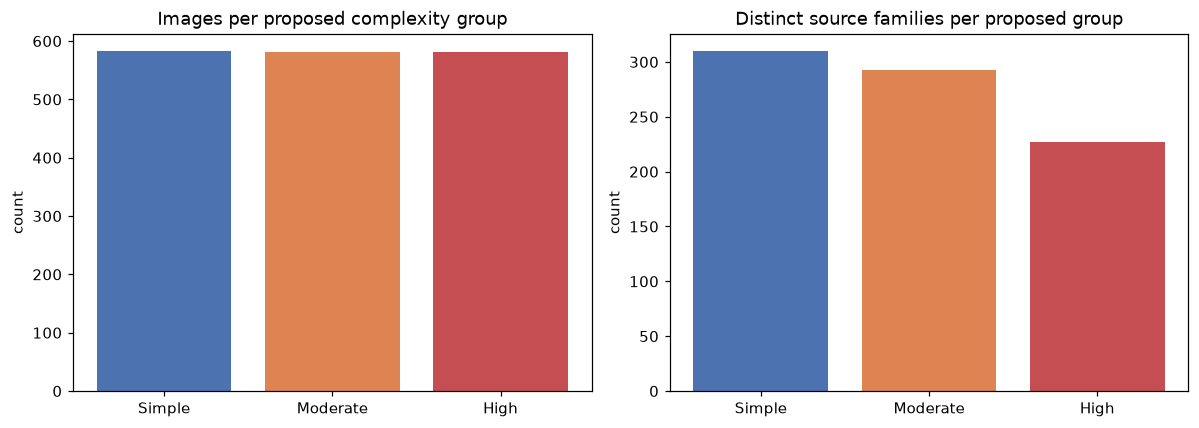

In [26]:

th = calib_config["thresholds"]
print(f"Candidate thresholds (tertiles of eligible composite-score distribution):")
print(f"  simple_max   = {th['simple_max']:.6f}")
print(f"  moderate_max = {th['moderate_max']:.6f}")
print(f"  label        = {th['label']}")
print()
counts = calib_summary["group_image_counts"]
fam_counts = calib_summary["group_independent_family_counts"]
print(f"{'Group':10s} {'Images':>8s} {'Families':>10s}")
for g in ("Simple", "Moderate", "High"):
    print(f"{g:10s} {counts[g]:8d} {fam_counts[g]:10d}")
print(f"\nBoundary-adjacent (flagged, within {th['boundary_adjacent_margin']:.4f} of a cut point): "
      f"{calib_summary['n_boundary_adjacent_samples']} / {calib_summary['n_eligible_rows']} eligible images")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Simple", "Moderate", "High"], [counts[g] for g in ("Simple", "Moderate", "High")], color=["#4C72B0", "#DD8452", "#C44E52"])
axes[0].set_title("Images per proposed complexity group")
axes[0].set_ylabel("count")
axes[1].bar(["Simple", "Moderate", "High"], [fam_counts[g] for g in ("Simple", "Moderate", "High")], color=["#4C72B0", "#DD8452", "#C44E52"])
axes[1].set_title("Distinct source families per proposed group")
axes[1].set_ylabel("count")
plt.tight_layout(); plt.show()


### 3.8 Weight-sensitivity and bootstrap stability checks

In [27]:

ws = calib_summary["weight_sensitivity"]
print("Weight-sensitivity check (candidate alternative weightings, NOT XAI-tuned):")
for key in ("alt_weights_A_emphasise_luminance", "alt_weights_B_emphasise_glcm_entropy"):
    w = ws[key]
    print(f"  {key}: weights={w['weights']}, "
          f"n_images_changed_group_vs_baseline={w['n_images_changed_group_vs_baseline']} "
          f"({w['fraction_images_changed_group_vs_baseline']:.1%})")

bs = calib_summary["bootstrap_stability"]
print()
print("Bootstrap stability (500 resamples, fixed seed):")
print(f"  simple_max   std={bs['simple_max_bootstrap']['std']:.5f} (point estimate {bs['simple_max_bootstrap']['point_estimate']:.5f})")
print(f"  moderate_max std={bs['moderate_max_bootstrap']['std']:.5f} (point estimate {bs['moderate_max_bootstrap']['point_estimate']:.5f})")


Weight-sensitivity check (candidate alternative weightings, NOT XAI-tuned):
  alt_weights_A_emphasise_luminance: weights={'luminance_variation': 0.6, 'glcm_entropy': 0.2, 'colour_variation': 0.2}, n_images_changed_group_vs_baseline=360 (20.6%)
  alt_weights_B_emphasise_glcm_entropy: weights={'luminance_variation': 0.2, 'glcm_entropy': 0.6, 'colour_variation': 0.2}, n_images_changed_group_vs_baseline=326 (18.7%)

Bootstrap stability (500 resamples, fixed seed):
  simple_max   std=0.01753 (point estimate -0.37460)
  moderate_max std=0.03282 (point estimate 0.25055)


### 3.9 Representative training images per proposed group

Genuine representative TRAIN-split images, one per proposed group (central/median composite-score example).
Full 30-row review package (central + boundary-adjacent + feature-disagreement cases): ../results/calibration/expert_review_package_v1.csv


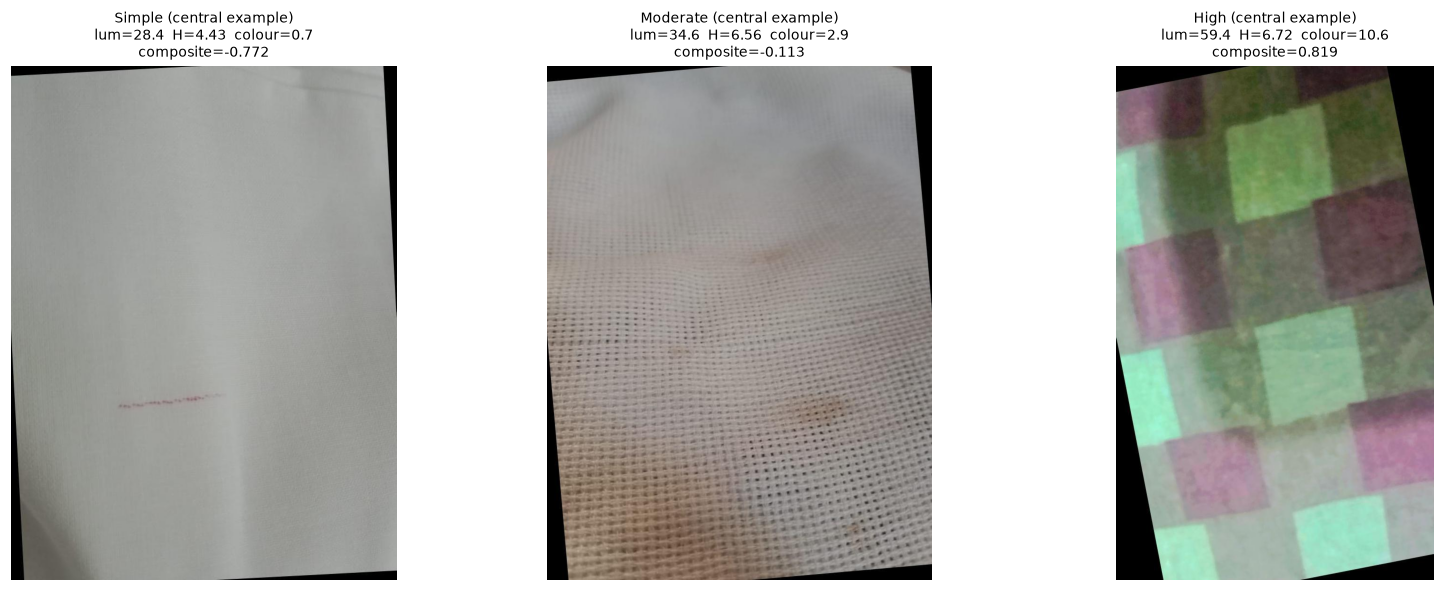

In [28]:

import cv2

with open(CALIB_DIR / "expert_review_package_v1.csv", newline="", encoding="utf-8") as f:
    review_rows = list(csv.DictReader(f))

central_by_group = {
    g: next(r for r in review_rows if r["proposed_group"] == g and r["selection_reason"] == f"representative_central_{g.lower()}")
    for g in ("Simple", "Moderate", "High")
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (g, row) in zip(axes, central_by_group.items()):
    img_rgb = cv2.cvtColor(cv2.imread(str(REPO_ROOT / row["relative_image_path"])), cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb); ax.axis("off")
    ax.set_title(f"{g} (central example)\nlum={float(row['luminance_variation']):.1f}  "
                 f"H={float(row['glcm_entropy']):.2f}  colour={float(row['colour_variation']):.1f}\n"
                 f"composite={float(row['composite_score']):.3f}", fontsize=9)
plt.tight_layout(); plt.show()
print("Genuine representative TRAIN-split images, one per proposed group (central/median composite-score example).")
print("Full 30-row review package (central + boundary-adjacent + feature-disagreement cases): "
      "../results/calibration/expert_review_package_v1.csv")


### 3.10 Calibration limitations (carried forward, not resolved)

1. **Box-vs-segmentation approximation** (F2.1A): GT bounding boxes over-exclude real
   background for elongated/diagonal defects; no pixel-accurate mask exists for Chenab.
2. **Resize-driven real-world GLCM distance confound** (quantified in
   `../reports/b2_task4_scale_mask_sensitivity.md`): up to ~4x difference in the physical
   spatial distance a nominal "distance=1" GLCM step represents, depending on original
   image resolution. Documented, not solved.
3. **`colour_variation` right-skew** biases the composite score's upper tail; not
   corrected in this stage (see `b2_task5_composite_scoring.md` §6).
4. **Composite-score weight sensitivity**: ~19–21% of images change group under
   alternative, equally-plausible weightings — the single-score ranking is not robust to
   this choice, even though group *sizes* stay stable.
5. **Family clustering in the High group**: the family:image ratio shrinks from Simple
   (0.53) to High (0.39) — a handful of source families contribute disproportionately
   many images to the High-complexity stratum. Any future per-stratum evaluation
   sampling should be family-aware.
6. **Provisional thresholds reused unchanged**: `max_defect_coverage=0.70` and
   `min_valid_pairs=500` are inherited from F2.1A/F2.1B1, not re-derived here. The full
   1,900-image dataset shows a strongly bimodal `glcm_valid_pair_count` distribution (0
   or ≫1,075 pairs; nothing in between), so `min_valid_pairs` has not actually been the
   deciding factor for any real sample yet.

### 3.11 Expert review status

**Expert review status: pending.** A 30-sample QC review package
(`../results/calibration/expert_review_package_v1.csv`) has been prepared — central,
boundary-adjacent, and feature-disagreement examples per group, with genuinely blank
`independent_expert_judgment` / `expert_comments` / `disagreement_flag` / `review_status`
columns. **No disagreement flags, comments, or review statuses have been fabricated.**
**These thresholds are provisional and must not be adjusted using any future
Grad-CAM/Grad-CAM++/XAI-metric result** — doing so would make any later
complexity-stratified XAI evaluation circular (see Section 2.4 and
`../reports/task7_panel_defense_masked_glcm.md` §5 for the full argument, which applies
unchanged here).

**Sections 4–9 below are now fully implemented.**

At the time of the original F2.1 development stage, Sections 4–9 had not yet been
implemented. These sections were subsequently completed through F2.3 and F2.4,
including detection-targeted Grad-CAM/Grad-CAM++ generation, quantitative XAI
reliability metrics (localization, faithfulness, stability), sanity checks, and
runtime evaluation. The final PP1 notebook (this document) now consolidates these
completed experiments together with the F2.5 complexity-stratified statistical
analysis and the F2.5-S1 weighting-sensitivity amendment.


## Section 3B — F2.1B3 Robustness Audit + Expert-Review Readiness

**Stage F2.1B3: robustness audit + expert-review readiness. Still NOT a calibration
freeze.** This section reports genuine output from six new audit tasks run against the
real F2.1B2 artifacts: (1) an independent re-verification that every F2.1B2 claim
reproduces exactly from stored config + raw features, (2) a systematic composite-score
weighting-robustness characterisation (7 weighting schemes, confusion matrices,
stable-vs-unstable classification), (3) a GLCM image-scale (resize) sensitivity check
with an explicit pixel-vs-physical-scale caveat, (4) a source-family and defect-class
exclusion-bias audit, (5) an artifact-safety checksum guard, and (6) an improved
(v2), family-diversity-capped QC expert-review package with a genuine blind-review
split. Full detail: `../reports/b3_panel_defense_robustness.md` and the Task-specific
JSON/CSV outputs in `../results/calibration/b3_*`.

**Execution note (honesty disclosure, same as Sections 2/3):** no live Jupyter kernel is
available in this environment. Every code cell below was executed exactly as written via
a plain Python process (`backend/.venv`) against the real repository files produced by
this stage's own scripts, and its genuine stdout / genuine rendered PNG figures are
embedded as that cell's outputs. Nothing below is hand-written, estimated, or
fabricated.

### 3B.1 Task 1 — Independent reproducibility confirmation


In [27]:

with open(CALIB_DIR / "b3_task1_audit_report.json", encoding="utf-8") as f:
    audit = json.load(f)

a = audit["task_A_row_count_crosscheck"]
b = audit["task_B_eligibility_recomputation"]
c = audit["task_C_rejection_reason_specificity"]
d = audit["task_D_composite_score_and_threshold_recomputation"]
e = audit["task_E_source_family_counts"]

print("Task A -- row-count cross-check against split_manifest.csv / train_manifest.csv:")
print(f"  n_train_rows_in_split_manifest={a['n_train_rows_in_split_manifest']}, "
      f"n_rows_in_train_features_v1_full_csv={a['n_rows_in_train_features_v1_full_csv']}, "
      f"all_1900_accounted_for={a['all_1900_accounted_for']}")
print()
print("Task B -- eligibility INDEPENDENTLY RECOMPUTED from raw per-row quality flags "
      "(not trusting the stored 'eligible' column):")
print(f"  recomputed eligible={b['n_recomputed_eligible']}, ineligible={b['n_recomputed_ineligible']} "
      f"(expected 1747/153, matches={b['matches_expected_1747_153']})")
print(f"  rows where stored value differs from recomputed: {b['n_rows_where_stored_differs_from_recomputed']}")
print()
print("Task C -- rejection-reason specificity (153 ineligible rows):")
print(f"  all_reasons_specific={c['all_reasons_specific']}, distinct reasons used: {c['distinct_reason_labels_used']}")
print()
print("Task D -- composite score + tertile thresholds RECOMPUTED from calibration_v1.json's "
      "stored normalization params, via the real scoring.py functions:")
print(f"  recomputed simple_max={d['recomputed_simple_max']:.6f} (stored {d['stored_simple_max']:.6f}, "
      f"abs diff={d['threshold_abs_diff']['simple_max']:.2e})")
print(f"  recomputed moderate_max={d['recomputed_moderate_max']:.6f} (stored {d['stored_moderate_max']:.6f}, "
      f"abs diff={d['threshold_abs_diff']['moderate_max']:.2e})")
print(f"  recomputed group image counts: {d['recomputed_group_image_counts']} "
      f"(expected Simple 583/Moderate 582/High 582, matches={d['matches_expected_583_582_582']})")
print(f"  group mismatches vs stored train_composite_scores_v1.csv: {d['n_group_mismatches_vs_stored_csv']}")
print(f"  composite-score numeric mismatches (>1e-9) vs stored CSV: {d['n_composite_score_numeric_mismatches_vs_stored_csv']}")
print()
print("Task E -- independent source-family (group_id) counts per group:")
print(f"  {e['recomputed_family_counts']} (expected Simple 310/Moderate 293/High 227, "
      f"matches={e['matches_expected_310_293_227']})")
print()
print(f"OVERALL VERDICT: {audit['overall_reproducibility_verdict']}")
print(f"Discrepancies found: {audit['discrepancies'] if audit['discrepancies'] else 'NONE'}")


Task A -- row-count cross-check against split_manifest.csv / train_manifest.csv:
  n_train_rows_in_split_manifest=1900, n_rows_in_train_features_v1_full_csv=1900, all_1900_accounted_for=True

Task B -- eligibility INDEPENDENTLY RECOMPUTED from raw per-row quality flags (not trusting the stored 'eligible' column):
  recomputed eligible=1747, ineligible=153 (expected 1747/153, matches=True)
  rows where stored value differs from recomputed: 0

Task C -- rejection-reason specificity (153 ineligible rows):
  all_reasons_specific=True, distinct reasons used: ['background_coverage_insufficient_provisional_70pct_rule', 'luminance_invalid_or_nonfinite']

Task D -- composite score + tertile thresholds RECOMPUTED from calibration_v1.json's stored normalization params, via the real scoring.py functions:
  recomputed simple_max=-0.374605 (stored -0.374605, abs diff=0.00e+00)
  recomputed moderate_max=0.250552 (stored 0.250552, abs diff=0.00e+00)
  recomputed group image counts: {'Simple': 583, 'Mo

### 3B.2 Task 2 — Composite-score weighting robustness (7 schemes)

Baseline (equal-weight) counts: {'Simple': 583, 'Moderate': 582, 'High': 582}

Scheme                                        weights (lum, glcm, colour)   n_changed     frac
alt_A_emphasise_luminance_0.6_0.2_0.2         (0.6, 0.2, 0.2)                     360   20.6%
alt_B_emphasise_glcm_0.2_0.6_0.2              (0.2, 0.6, 0.2)                     326   18.7%
alt_C_emphasise_colour_0.2_0.2_0.6            (0.2, 0.2, 0.6)                     154    8.8%
extreme_luminance_only_1_0_0                  (1.0, 0.0, 0.0)                     691   39.6%
extreme_glcm_only_0_1_0                       (0.0, 1.0, 0.0)                     589   33.7%
extreme_colour_only_0_0_1                     (0.0, 0.0, 1.0)                     533   30.5%

Stability across ALL 7 schemes (baseline + 3 plausible alternatives + 3 extreme single-feature bounds): 534 stable / 1213 unstable (69.4% unstable)
Families with >=1 unstable image: 525; fully-stable families: 131
Confusion matrices: baseline (equal-weight) gro

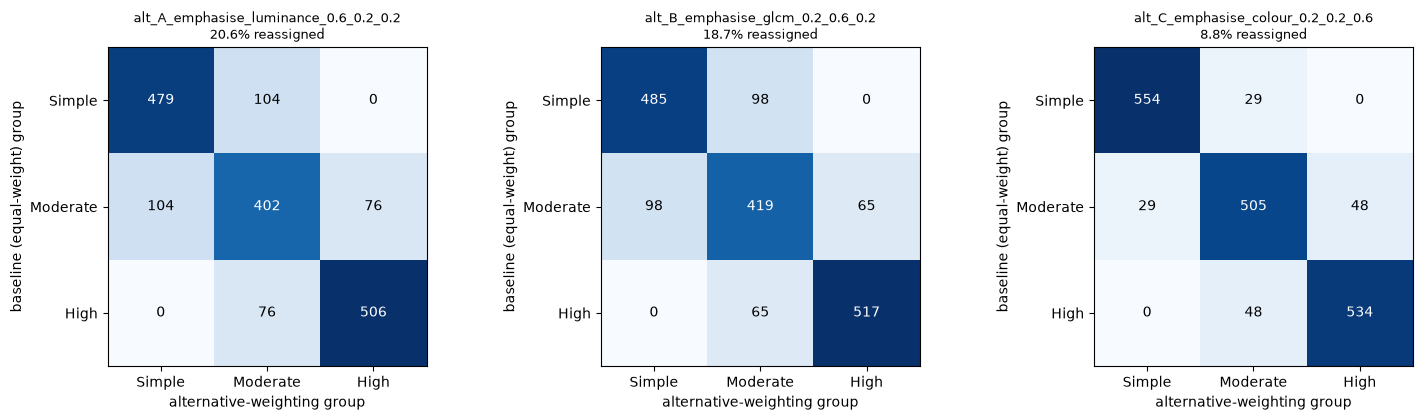

In [28]:

with open(CALIB_DIR / "b3_task2_weight_sensitivity_summary.json", encoding="utf-8") as f:
    ws2 = json.load(f)

print("Baseline (equal-weight) counts:", ws2["baseline_counts"])
print()
print(f"{'Scheme':45s} {'weights (lum, glcm, colour)':28s} {'n_changed':>10s} {'frac':>8s}")
for name, alt in ws2["per_alternative_weighting_results"].items():
    w = alt["weights"]
    wtup = (round(w["luminance_variation"], 2), round(w["glcm_entropy"], 2), round(w["colour_variation"], 2))
    print(f"{name:45s} {str(wtup):28s} {alt['n_images_changed_group_vs_baseline']:>10d} "
          f"{alt['fraction_images_changed_group_vs_baseline']:>7.1%}")

stab = ws2["stability_across_all_7_schemes"]
print()
print(f"Stability across ALL 7 schemes (baseline + 3 plausible alternatives + 3 extreme "
      f"single-feature bounds): {stab['n_stable_images']} stable / {stab['n_unstable_images']} unstable "
      f"({stab['fraction_unstable']:.1%} unstable)")
print(f"Families with >=1 unstable image: {stab['n_families_with_at_least_one_unstable_image']}; "
      f"fully-stable families: {stab['n_families_fully_stable']}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
groups = ["Simple", "Moderate", "High"]
for ax, key in zip(axes, ["alt_A_emphasise_luminance_0.6_0.2_0.2", "alt_B_emphasise_glcm_0.2_0.6_0.2",
                           "alt_C_emphasise_colour_0.2_0.2_0.6"]):
    cm = ws2["per_alternative_weighting_results"][key]["confusion_matrix_baseline_rows_alt_cols"]
    mat = [[cm[b][a] for a in groups] for b in groups]
    im = ax.imshow(mat, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, mat[i][j], ha="center", va="center",
                    color="white" if mat[i][j] > 250 else "black", fontsize=10)
    ax.set_xticks(range(3)); ax.set_xticklabels(groups)
    ax.set_yticks(range(3)); ax.set_yticklabels(groups)
    ax.set_xlabel("alternative-weighting group"); ax.set_ylabel("baseline (equal-weight) group")
    frac = ws2["per_alternative_weighting_results"][key]["fraction_images_changed_group_vs_baseline"]
    ax.set_title(f"{key}\n{frac:.1%} reassigned", fontsize=9)
plt.tight_layout(); plt.show()
print("Confusion matrices: baseline (equal-weight) group (rows) vs each alternative weighting's group (columns).")
print("Off-diagonal cells = images that changed complexity group purely from the weighting choice.")


### 3B.3 Task 3 — GLCM image-scale (resize) sensitivity

In [29]:

with open(CALIB_DIR / "b3_task3_scale_sensitivity_summary.json", encoding="utf-8") as f:
    ss3 = json.load(f)

print("Preprocessing configs tested (differ ONLY in resize_long_edge):")
for name, cfg in ss3["preprocess_configs_tested"].items():
    print(f"  {name}: resize_long_edge={cfg['resize_long_edge']}")
print()
print("Default-512 vs no-resize, by ORIGINAL-resolution bucket (n=10 per bucket):")
for bucket, stats in ss3["by_resolution_bucket_default_vs_no_resize"].items():
    print(f"  {bucket:8s} n={stats['n_images']:2d}  mean|delta GLCM entropy|={stats['mean_abs_delta_glcm_entropy_default_vs_no_resize']:.4f}"
          f"  mean resize_scale_factor={stats['mean_resize_scale_factor_default_512']}"
          f"  mean real-world distance-1 equivalent={stats['mean_real_world_distance1_equivalent_px']:.3f}px" if stats['mean_resize_scale_factor_default_512'] else f"  {bucket:8s} n={stats['n_images']:2d} (no resize applied; scale factor 1.0)")
print()
pw = ss3["pairwise_config_comparison"]["default_512_vs_no_resize"]
print(f"Overall (n={pw['n_comparable_glcm']}): mean|delta GLCM entropy|={pw['mean_abs_delta_glcm_entropy']:.4f}, "
      f"max|delta|={pw['max_abs_delta_glcm_entropy']:.4f}")
print(f"Group-assignment flips under the SHIPPED calibration (same thresholds applied to both configs): "
      f"{pw['n_group_assignment_flips_under_shipped_calibration']} / {pw['n_both_eligible_and_scored_under_shipped_calibration']}")
print()
print("CAVEAT (normalization held fixed):", ss3["caveat_normalization_held_fixed"])
print()
print("CAVEAT (pixel-scale vs physical-scale -- do not conflate):")
print(ss3["caveat_pixel_vs_physical_scale"])


Preprocessing configs tested (differ ONLY in resize_long_edge):
  default_512: resize_long_edge=512
  alt_1024: resize_long_edge=1024
  no_resize: resize_long_edge=100000

Default-512 vs no-resize, by ORIGINAL-resolution bucket (n=10 per bucket):
  small    n=10  mean|delta GLCM entropy|=0.0000  mean resize_scale_factor=1.0  mean real-world distance-1 equivalent=1.000px
  medium   n=10  mean|delta GLCM entropy|=0.3399  mean resize_scale_factor=0.49401  mean real-world distance-1 equivalent=2.033px
  large    n=10  mean|delta GLCM entropy|=0.7135  mean resize_scale_factor=0.2610812  mean real-world distance-1 equivalent=3.836px

Overall (n=30): mean|delta GLCM entropy|=0.3512, max|delta|=0.9390
Group-assignment flips under the SHIPPED calibration (same thresholds applied to both configs): 0 / 25

CAVEAT (normalization held fixed): composite_score/group columns reuse the SHIPPED calibration_v1.json normalization parameters and tertile thresholds (computed under the default_512 protocol) 

### 3B.4 Task 4 — Source-family and defect-class exclusion-bias audit

In [30]:

with open(CALIB_DIR / "b3_task4_family_bias_audit.json", encoding="utf-8") as f:
    fb4 = json.load(f)

print(f"Overall exclusion rate: {fb4['overall_exclusion_rate']:.1%}  "
      f"(coverage-rule-specific: {fb4['overall_coverage_rule_exclusion_rate']:.1%})")
print()
print("Per-defect-class exclusion rate (image-level, multi-label; classes with >=10 images):")
print(f"{'class':16s} {'n_total':>8s} {'n_excluded':>11s} {'rate':>8s}")
for name, stats in sorted(fb4["per_defect_class_exclusion_rates"].items(),
                           key=lambda kv: kv[1]["exclusion_rate"] or 0, reverse=True):
    if stats["n_total_images_with_class"] < 10:
        continue
    print(f"{name:16s} {stats['n_total_images_with_class']:>8d} {stats['n_excluded']:>11d} "
          f"{stats['exclusion_rate']:>7.1%}")
print()
print("Classes disproportionately excluded overall (>=1.5x the overall exclusion rate, n>=10):",
      fb4["disproportionately_excluded_classes_overall_1.5x_rule"])
print("Classes disproportionately excluded SPECIFICALLY by the 70%-coverage rule:",
      fb4["disproportionately_coverage_excluded_classes_1.5x_rule"])
print()
print("Per-group source-family concentration (top-10 families' combined share of that group):")
for g, stats in fb4["per_group_family_concentration"].items():
    print(f"  {g:10s} n_distinct_families={stats['n_distinct_families']:3d}  "
          f"top10_combined={stats[f'top_10_families_combined_pct_of_group']:.1f}%  "
          f"max_single_family={stats['max_single_family_pct_of_group']:.2f}%")
print()
print("Per-group sample-type (background-type) composition:")
for g, counts in fb4["per_group_sample_type_composition"].items():
    print(f"  {g:10s} {counts}")


Overall exclusion rate: 8.1%  (coverage-rule-specific: 6.1%)

Per-defect-class exclusion rate (image-level, multi-label; classes with >=10 images):
class             n_total  n_excluded     rate
baekra                158          95   60.1%
color issues           79          25   31.6%
gray stitch           222          13    5.9%
cut                   269          14    5.2%
selvet                214           5    2.3%
stain                 665           1    0.2%
contamination         142           0    0.0%
__negative_no_class__      154           0    0.0%

Classes disproportionately excluded overall (>=1.5x the overall exclusion rate, n>=10): ['baekra', 'color issues']
Classes disproportionately excluded SPECIFICALLY by the 70%-coverage rule: ['baekra', 'color issues']

Per-group source-family concentration (top-10 families' combined share of that group):
  Simple     n_distinct_families=310  top10_combined=9.1%  max_single_family=1.03%
  Moderate   n_distinct_families=293  top10

**Reading these numbers:** `baekra` (60.1% excluded, 45.0% by the coverage rule alone)
and `color issues` (31.6% / 21.5%) are excluded at roughly 4-8x the dataset's overall
8.1% exclusion rate -- consistent with the task brief's hypothesis that defect classes
producing large/elongated GT boxes get disproportionately filtered by the provisional
70%-coverage rule. `contamination` and `stain` are essentially never excluded (0.0% /
0.15%). Source-family concentration grows mildly but consistently from Simple -> High
(top-10-families' combined share: 9.1% -> 11.9% -> 15.1%; max single family: 1.0% ->
1.7% -> 1.9%) -- a real, directionally-confirmed gradient, but NOT an extreme
few-families-dominate skew (no single family exceeds ~2% of any group). Defect-class
composition also shifts markedly by group (`stain` is 68% of Simple; `cut` is 35% of
High), meaning complexity group and defect class are **confounded**, not independent
axes, in this dataset.

**Proposed F2.2 sampling strategy (proposed here, NOT implemented in this stage):**
when later selecting complexity-stratified evaluation subsets, cap at most **K=2** images
per source family (`group_id`) per complexity group (mirroring the cap already
applied to the Task 6 v2 expert-review package, see Section 3B.5/3B.7), and report
defect-class composition per stratum alongside any complexity-stratified XAI result, so
a reviewer can distinguish "the High group performs differently" from "the High group
happens to be mostly `cut` defects."

### 3B.5 Stable vs. ambiguous representative samples


STABLE examples: same complexity group under all 7 weighting schemes (baseline + 3 plausible + 3 extremes).
UNSTABLE examples: group assignment genuinely changes across weighting schemes -- the composite
score's single-number ranking is NOT robust to the combination method for these specific images.


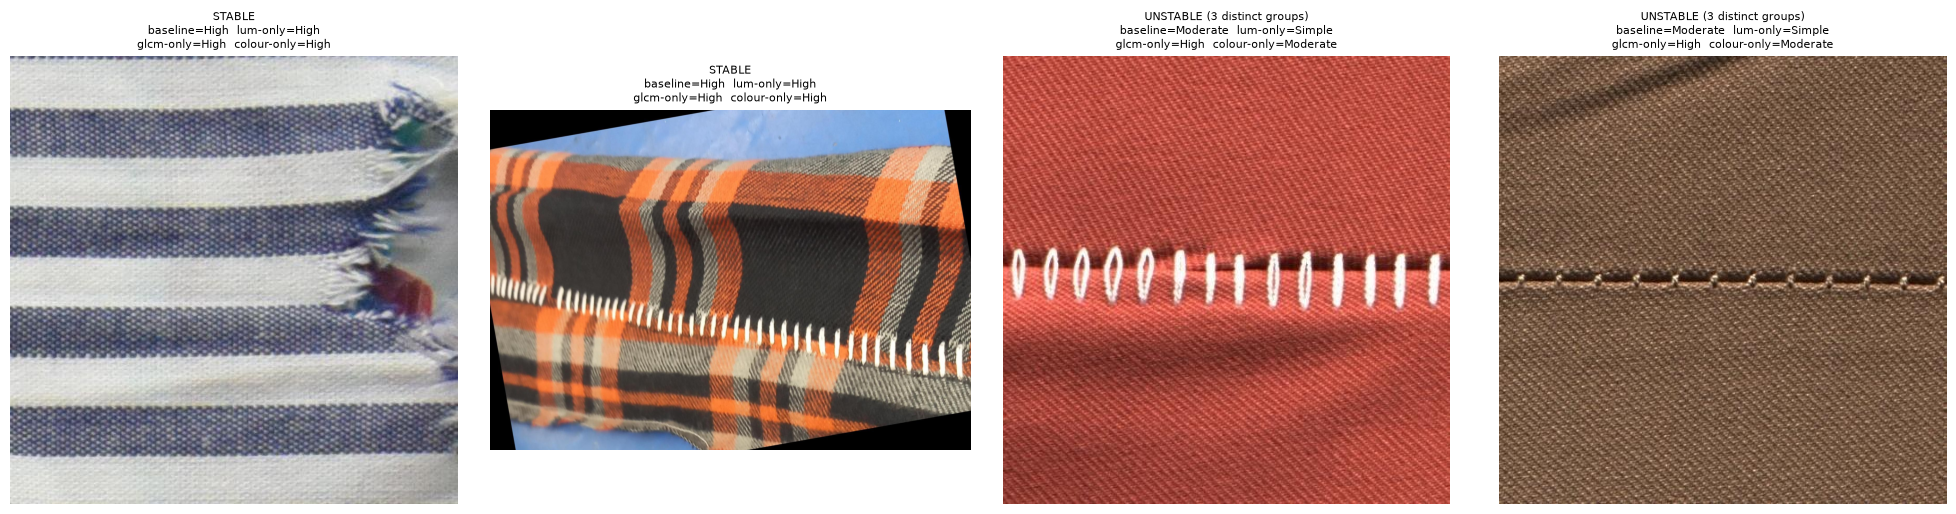

In [31]:

with open(CALIB_DIR / "weight_sensitivity_v2.csv", newline="", encoding="utf-8") as f:
    ws_rows = list(csv.DictReader(f))

stable_examples = [r for r in ws_rows if r["stable_across_all_weightings"] == "True"][:2]
unstable_examples = [r for r in ws_rows if r["stable_across_all_weightings"] == "False"
                      and r["n_distinct_groups_across_schemes"] == "3"][:2]

with open(CALIB_DIR / "train_features_v1_full.csv", newline="", encoding="utf-8") as f:
    rel_path_by_id = {r["image_id"]: r["relative_path"] for r in csv.DictReader(f)}

examples = stable_examples + unstable_examples
labels = ["STABLE"] * len(stable_examples) + ["UNSTABLE (3 distinct groups)"] * len(unstable_examples)

fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5))
if len(examples) == 1:
    axes = [axes]
for ax, row, label in zip(axes, examples, labels):
    rel_path = rel_path_by_id.get(row["image_id"], "")
    img_rgb = cv2.cvtColor(cv2.imread(str(REPO_ROOT / rel_path)), cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb); ax.axis("off")
    ax.set_title(f"{label}\nbaseline={row['group_baseline_equal']}  "
                 f"lum-only={row['group_extreme_luminance_only_1_0_0']}\n"
                 f"glcm-only={row['group_extreme_glcm_only_0_1_0']}  "
                 f"colour-only={row['group_extreme_colour_only_0_0_1']}", fontsize=8)
plt.tight_layout(); plt.show()
print("STABLE examples: same complexity group under all 7 weighting schemes (baseline + 3 plausible + 3 extremes).")
print("UNSTABLE examples: group assignment genuinely changes across weighting schemes -- the composite")
print("score's single-number ranking is NOT robust to the combination method for these specific images.")


### 3B.6 Updated / expanded limitations (F2.1B3)

In addition to the F2.1B2 limitations already recorded in Section 3.10, this stage's
audit surfaces the following, all evidence-based (not hypothetical):

1. **Weighting choice is a materially larger source of group-assignment instability than
   resampling noise.** Even the most conservative plausible alternative weighting
   (emphasise colour, 0.2/0.2/0.6) reassigns 8.8% of eligible images; emphasising
   luminance or GLCM texture reassigns 18.7-20.6%; the three extreme single-feature
   baselines (which deliberately bound the problem) reassign 30.5-39.6%. Across all 7
   schemes tested, only 30.6% of eligible images keep the same group label in every
   single scheme -- 69.4% change group under at least one plausible-or-extreme
   alternative. This does not mean the equal-weight composite score is wrong; it means
   **which specific images land in which group is highly sensitive to a choice (the
   weighting) that has not been validated against any external ground truth.**
2. **Defect class and complexity group are confounded, not independent.** `stain`
   dominates the Simple group (68% of its eligible images); `cut` dominates the High
   group (35%). Any later complexity-stratified XAI comparison must account for this
   confound explicitly (e.g. by also reporting per-class breakdowns within each
   stratum) rather than attributing a cross-group performance difference to complexity
   alone.
3. **The 70%-coverage exclusion rule is not class-neutral.** `baekra` and `color issues`
   are excluded 4-8x more often than the dataset average, specifically via the coverage
   rule. The 1,747-eligible-image population is therefore not a class-representative
   subsample of the full 1,900-image TRAIN split -- it systematically under-represents
   these two classes' background-complexity measurements.
4. **GLCM entropy is measurably resize-sensitive, but (in this n=30 systematic sample)
   this did not yet flip any group assignment under the shipped calibration.** Mean
   |delta| GLCM entropy between the default-512 and no-resize configs grows from ~0.0
   bits (small, never-resized images) to ~0.71 bits (large images, confirming and
   extending F2.1B2's n=12 finding) -- a real, resolution-dependent measurement
   artefact -- but 0 of 25 comparably-scored images changed complexity group when the
   SAME shipped thresholds were applied to both configs. This is reassuring for the
   CURRENT calibration's practical stability, but is explicitly NOT evidence that the
   artefact is harmless in general (a larger/different sample, or a from-scratch
   recalibration under a different resize protocol, could behave differently -- see the
   explicit caveat in Section 3B.3).
5. **All scale-sensitivity findings in this stage are PIXEL-scale, not PHYSICAL-scale,
   normalization.** No DPI, sensor-distance, or physical fabric-sample-size metadata
   exists anywhere in this dataset's manifests. Nothing in this stage claims, or should
   be read as claiming, that any resize convention is more "physically correct" than
   another -- only that the choice is consistent within itself and measurably moves
   raw numbers.
6. **The QC expert-review package has not yet been reviewed by a human.** Zero
   judgments exist anywhere in this repository. Only one QC reviewer is currently known
   to be available (status: assumed, not confirmed) -- see Section 3B.7.

### 3B.7 Expert-validation status (explicit)

**No expert review has occurred.** This stage (F2.1B3) produced an IMPROVED (v2)
30-sample QC review package (`../results/calibration/expert_review_package_v2_full.csv`)
with an explicit per-source-family cap (max 2 images per family per group, vs. v1's
uncapped selection, which let one family contribute 3/10 of the High group) and a
genuine **blind-review split**:
`expert_review_package_v2_blind_for_reviewer.csv` (what a reviewer sees -- image path +
genuinely blank judgment columns only, row order deterministically shuffled) and
`expert_review_package_v2_reconciliation_key.csv` (the algorithm's proposed group +
measurements, to be joined back only after review). Reviewer instructions:
`../reports/qc_expert_review_instructions.md`.

**Number of QC experts currently available: unknown / assumed single-reviewer** -- no
information about reviewer availability was provided to this stage. A reusable Cohen's
kappa inter-rater-agreement function
(`../complexity/inter_rater_agreement.py`) has been implemented and unit-tested against
clearly-labelled synthetic/dummy data only (see `../tests/test_inter_rater_agreement.py`)
so that agreement can be computed immediately if/when a second reviewer becomes
available -- **no second reviewer's data has been fabricated anywhere in this
repository.**

**Bottom line:** the complexity protocol remains exactly what F2.1B2 declared it to be --
a provisional, non-frozen candidate -- and this stage's finding that composite-score
*group assignment* (not group *size*) is materially weighting-sensitive makes expert
review, not further unilateral threshold tuning, the right next step. See
`../reports/b3_panel_defense_robustness.md` for the full 5-point recommendation.


## Section 3C — F2.2A Validation Dataset and Ground-Truth Reference Audit

**Stage: F2.2A — validation dataset + ground-truth annotation METADATA audit ONLY.**
This section does **not** open any VALIDATION or TEST split image pixels, does not
run model inference or Grad-CAM/Grad-CAM++, and does not freeze complexity thresholds
or assign complexity groups to validation images (none of the TRAIN-derived provisional
thresholds from Section 3/3B are used anywhere below — VALID images have no complexity
labels at this stage, by design). It reports genuine, metadata-only findings from the
real Chenab VALID split (377 images) across six audit tasks: (1) authoritative
split-count verification, (2) GT bounding-box annotation parsing/validity audit, (3) a
bounding-box reference-quality investigation, (4) a reference-mask (AITEX) provenance
audit, (5) dataset composition analysis, and (6)/(7) a *proposed, not executed* sampling
protocol and metric-eligibility rule definitions for future stages. Full detail:
`../reports/f22a_task3_bbox_reference_quality.md`,
`../reports/f22a_task4_reference_mask_provenance.md`,
`../reports/f22a_task6_sampling_protocol_proposal.md`,
`../reports/f22a_task7_metric_reference_eligibility.md`, and the JSON/CSV outputs in
`../results/validation_audit/`.

*(Numbering note: this is labelled Section 3C rather than "Section 3" verbatim, because
Sections 3 and 3B already exist from F2.1B2/F2.1B3 and contain genuine prior content
that must not be renumbered or destroyed. 3C continues that existing numbering
sequence and sits, correctly, before Section 4's still-unimplemented Grad-CAM work.)*

**Execution note (honesty disclosure, same as Sections 2/3/3B):** no live Jupyter
kernel is available in this environment. Every code cell below was executed exactly as
written via a plain Python process (`backend/.venv`) against the real repository files
produced by this stage's own scripts, and its genuine stdout / genuine rendered PNG
figure are embedded as that cell's outputs. Nothing below is hand-written, estimated,
or fabricated.

### 3C.1 Task 1/2 — Authoritative VALID split count + GT annotation audit


In [32]:
VALID_AUDIT_DIR = REPO_ROOT / "research/component1/function2/results/validation_audit"

with open(VALID_AUDIT_DIR / "f22a_task1_2_valid_audit_report.json", encoding="utf-8") as f:
    valid_audit = json.load(f)

t1 = valid_audit["task1_split_metadata_verification"]
t2 = valid_audit["task2_annotation_audit_summary"]

print("Task 1 -- authoritative VALID split count (read exclusively from split_manifest.csv's")
print("own 'split' column via manifest_loader.load_split_manifest(); never inferred from")
print("filename substrings -- F2.1A found a TRAIN image can contain 'chenab_valid_' in its")
print("own image_id/filename, e.g. image_id='chenab_valid_augmented_00002841_...' with split='train'):")
print(f"  n_valid_rows_in_split_manifest={t1['n_valid_rows_in_split_manifest']} "
      f"(expected {t1['expected_valid_count']}, matches={t1['matches_expected_377']})")
print(f"  full split counts: {t1['full_split_counts']}")
print(f"  n_distinct_group_ids_in_valid={t1['n_distinct_group_ids_in_valid']}")
print()
print("Task 2 -- GT annotation metadata audit (377 VALID images, label .txt files only,")
print("no image pixels opened):")
print(f"  n_missing_annotation={t2['n_missing_annotation']}, n_confirmed_negative={t2['n_confirmed_negative']}, "
      f"n_malformed_annotation={t2['n_malformed_annotation']}")
print(f"  n_single_defect_images={t2['n_single_defect_images']}, n_multi_defect_images={t2['n_multi_defect_images']}")
print(f"  n_total_well_formed_boxes={t2['n_total_well_formed_boxes']}")
print(f"  out-of-[0,1]-bounds boxes={t2['n_boxes_out_of_0_1_bounds']}, non-positive w/h={t2['n_boxes_non_positive_wh']}, "
      f"invalid class id={t2['n_boxes_invalid_class_id']}")
print()
print(f"Overall verdict: {valid_audit['overall_verdict']}")
print(f"Discrepancies found: {valid_audit['discrepancies'] if valid_audit['discrepancies'] else 'NONE'}")


Task 1 -- authoritative VALID split count (read exclusively from split_manifest.csv's
own 'split' column via manifest_loader.load_split_manifest(); never inferred from
filename substrings -- F2.1A found a TRAIN image can contain 'chenab_valid_' in its
own image_id/filename, e.g. image_id='chenab_valid_augmented_00002841_...' with split='train'):
  n_valid_rows_in_split_manifest=377 (expected 377, matches=True)
  full split counts: {'train': 1900, 'valid': 377, 'test': 378}
  n_distinct_group_ids_in_valid=314

Task 2 -- GT annotation metadata audit (377 VALID images, label .txt files only,
no image pixels opened):
  n_missing_annotation=0, n_confirmed_negative=32, n_malformed_annotation=0
  n_single_defect_images=239, n_multi_defect_images=106
  n_total_well_formed_boxes=520
  out-of-[0,1]-bounds boxes=0, non-positive w/h=0, invalid class id=0

Overall verdict: VALID_SPLIT_METADATA_AND_ANNOTATIONS_AUDITED_NO_BLOCKING_DISCREPANCIES
Discrepancies found: NONE


### 3C.2 Task 3 — Bounding-box reference quality (these are BOXES, not pixel-level masks)

A GT bounding box can confirm "the defect is somewhere inside this rectangle," nothing
finer — it cannot support a precise pixel-level IoU against a predicted segmentation or
saliency region, only box-level comparisons. Full discussion:
`../reports/f22a_task3_bbox_reference_quality.md`.


In [33]:
with open(VALID_AUDIT_DIR / "f22a_task3_bbox_quality.json", encoding="utf-8") as f:
    bbox_quality = json.load(f)

print("Box-geometry quality flags (520 well-formed GT boxes, VALID split):")
print(f"  large (w or h > 0.9): {bbox_quality['large_boxes']['n_total']} ({bbox_quality['large_boxes']['pct_of_all_boxes']}%)")
print(f"  full-span (w or h >= 0.98): {bbox_quality['full_span_boxes']['n_total']} ({bbox_quality['full_span_boxes']['pct_of_all_boxes']}%)")
print(f"  elongated (aspect ratio >= 5.0): {bbox_quality['elongated_boxes']['n_total']} ({bbox_quality['elongated_boxes']['pct_of_all_boxes']}%)")
print()
print(f"{'class':16s} {'n_boxes':>8s} {'%large':>8s} {'%full-span':>11s} {'%elongated':>11s}")
for cls, v in bbox_quality["by_defect_class"].items():
    print(f"{cls:16s} {v['n_boxes']:8d} {v['pct_large']:7.1f}% {v['pct_full_span']:10.1f}% {v['pct_elongated']:10.1f}%")
print()
ov = bbox_quality["overlap_analysis"]
print(f"Images with >=2 GT boxes: {ov['n_images_with_multiple_boxes']}; "
      f"images with >=1 overlapping pair (IoU>0): {ov['n_images_with_any_overlapping_pair_iou_gt_0']}; "
      f"max pairwise IoU observed: {ov['max_iou_observed']}; pairs with IoU>0.5: {ov['n_pairs_iou_gt_0_5']}")
print()
print(bbox_quality["explicit_statement"])


Box-geometry quality flags (520 well-formed GT boxes, VALID split):
  large (w or h > 0.9): 97 (18.65%)
  full-span (w or h >= 0.98): 61 (11.73%)
  elongated (aspect ratio >= 5.0): 55 (10.58%)

class             n_boxes   %large  %full-span  %elongated
stain                 177     3.4%        1.1%        3.4%
cut                    78     9.0%        2.6%        2.6%
selvet                 72    30.6%       20.8%       31.9%
gray stitch            63    44.4%       41.3%       27.0%
color issues           58    19.0%        8.6%        3.4%
baekra                 44    52.3%       25.0%        0.0%
contamination          28     0.0%        0.0%       17.9%

Images with >=2 GT boxes: 106; images with >=1 overlapping pair (IoU>0): 36; max pairwise IoU observed: 0.4619; pairs with IoU>0.5: 0

All findings in this task describe AXIS-ALIGNED BOUNDING BOXES, NOT pixel-level segmentation masks. A GT bounding box cannot support a precise pixel-level IoU against a predicted segmentation/heatma

### 3C.3 Task 4 — Reference-mask (AITEX) availability / provenance conclusion

Full audit: `../reports/f22a_task4_reference_mask_provenance.md`. Summary conclusion:

**No validly-linked pixel-level reference masks currently exist for any Chenab
VALID-split image.** The only mask data found anywhere in this repository (AITEX/AFID,
under `data-preprocessing/master_fabric_dataset/processed/research_subsets/`) belongs
to a different, independently-sourced public dataset: a disjoint identifier namespace
(`aitex_defect_...`/`aitex_nodefect_...` vs. `chenab_valid_...`), structurally different
image geometry (4096×256 grayscale strips vs. photographed garment images), an
incompatible defect-class taxonomy, **zero documented identity or coordinate-alignment
evidence** linking any AITEX mask to any Chenab image, and mask review performed by **AI
only, never a human expert** (`function2_mask_readiness.md`: *"All decisions are
AI-reviewed, not human-verified."*). The project's own `split_policy_rules.md` already
documents an explicit **"AITEX Policy: Separate Research Subsets Only."** No AI-generated
mask found anywhere in this repository may be treated as expert-validated absent actual
evidence — none currently exists.

### 3C.4 Task 5 — Dataset composition (metadata only; no TRAIN-derived complexity groups used)


Three DIFFERENT numbers are reported throughout and must never be conflated: (1) IMAGE counts -- number of distinct image_id values; (2) DEFECT-INSTANCE counts -- number of individual GT boxes (one image with 3 boxes contributes 1 to image counts and 3 to instance counts); (3) SOURCE-FAMILY counts -- number of distinct group_id values (pre-augmentation source photos).

IMAGE count=377, DEFECT-INSTANCE count=520, SOURCE-FAMILY count=314

class             n_images  n_instances  n_families
stain                  126          177         124
cut                     56           78          50
selvet                  43           72          21
gray stitch             45           63          45
color issues            18           58          15
baekra                  34           44          24
contamination           24           28          19

Positive images (>=1 GT box): 345; confirmed-negative images: 32
Single-defect images: 239; multi-defect images: 106; zero-box images: 32

Uni

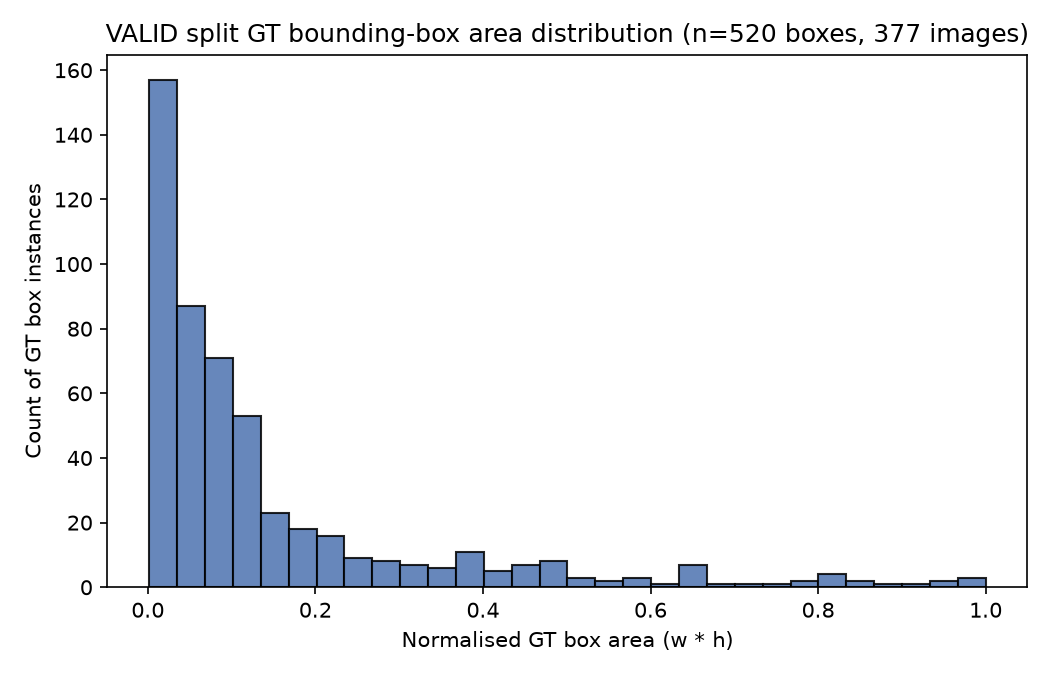

In [34]:
with open(VALID_AUDIT_DIR / "f22a_task5_composition_summary.json", encoding="utf-8") as f:
    comp = json.load(f)

print(comp["counting_convention"])
print()
tl = comp["top_level_counts"]
print(f"IMAGE count={tl['n_images']}, DEFECT-INSTANCE count={tl['n_defect_instances_total']}, "
      f"SOURCE-FAMILY count={tl['n_unique_source_families_group_id']}")
print()
print(f"{'class':16s} {'n_images':>9s} {'n_instances':>12s} {'n_families':>11s}")
for cls, v in comp["per_defect_class"].items():
    print(f"{cls:16s} {v['n_images_containing_this_class']:9d} {v['n_defect_instances_this_class']:12d} "
          f"{v['n_unique_source_families_with_this_class']:11d}")
print()
pn = comp["positive_vs_negative"]
sm = comp["single_vs_multi_defect_images"]
print(f"Positive images (>=1 GT box): {pn['n_positive_images_with_at_least_one_gt_box']}; "
      f"confirmed-negative images: {pn['n_confirmed_negative_images']}")
print(f"Single-defect images: {sm['n_single_defect_images']}; multi-defect images: {sm['n_multi_defect_images']}; "
      f"zero-box images: {sm['n_zero_box_images']}")
print()
fam = comp["source_family_distribution"]
print(f"Unique source families: {fam['n_unique_families']}; families with >=2 images: {fam['n_families_with_2_or_more_images']}; "
      f"max images from one family: {fam['max_images_from_a_single_family']}; "
      f"top-10 families combined = {fam['top10_combined_pct_of_images']}% of images")
print()
area = comp["bbox_area_distribution"]
print(f"GT box area (normalised, n={area['n_boxes']}): mean={area['mean']}, median={area['median']}, "
      f"stdev={area['stdev']}, min={area['min']}, max={area['max']}, Q1={area['q1']}, Q3={area['q3']}")
print()
proxy = comp["insufficient_background_metadata_proxy"]
print("METADATA-ONLY proxy flag (NOT the real pixel-based background-feature pipeline):")
print(" ", proxy["DISCLAIMER"])
print(f"  n_images flagged (largest GT box area > {proxy['area_threshold_used']}): "
      f"{proxy['n_images_with_largest_box_area_over_threshold']} ({proxy['pct_of_images']}% of images)")

import csv as _csv
with open(VALID_AUDIT_DIR / "valid_box_audit.csv", newline="", encoding="utf-8") as f:
    box_rows = list(_csv.DictReader(f))
areas = [float(r["area"]) for r in box_rows]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(areas, bins=30, color="#4C72B0", edgecolor="black", alpha=0.85)
ax.set_xlabel("Normalised GT box area (w * h)")
ax.set_ylabel("Count of GT box instances")
n_images_val = tl["n_images"]
ax.set_title(f"VALID split GT bounding-box area distribution (n={len(areas)} boxes, {n_images_val} images)")
plt.tight_layout()
plt.show()


### 3C.5 Task 6 — Proposed future sampling protocol (design only — NOT executed against real data)

Full spec: `../reports/f22a_task6_sampling_protocol_proposal.md`. It incorporates three
F2.1B3 findings directly: (a) 69.4% of eligible TRAIN images change complexity group
under at least one of 7 weighting schemes, so group membership must be treated as soft,
not authoritative; (b) per-group family counts are imbalanced (TRAIN: Simple 310 /
Moderate 293 / High 227 distinct families); (c) `baekra`/`color issues` are
disproportionately excluded on TRAIN by the 70%-coverage rule, and this stage's own
Task 3 confirms the same large/full-span-box tendency is directly visible in the raw
VALID-split box geometry for those classes. The protocol has two separate steps: a
deterministic **K=2-images-per-source-family-per-stratum cap**
(`complexity/sampling_protocol.py::apply_family_cap`), plus a **mandatory, separate**
class-composition report (`class_composition_report`) — because the family cap ALONE
does **not** fix class-composition confounding (classes are not evenly distributed
across families either). The cell below demonstrates the pure constraint logic on
hand-built **SYNTHETIC** data only — it is not a real selection, and no actual VALID
image has been chosen for anything.


In [35]:
from research.component1.function2.complexity.sampling_protocol import (
    SamplingCandidate, apply_family_cap, class_composition_report,
)

# SYNTHETIC demonstration data only -- NOT real VALID-split records, and NOT
# an actual selection for any future pilot. F2.2A does not select or output
# any real complexity-stratified image list; this cell exists purely to
# show the pure constraint-logic functions (Task 6) operate correctly.
synthetic_candidates = [
    SamplingCandidate("img_01", family_id="fam_A", stratum="Simple", defect_classes=("stain",)),
    SamplingCandidate("img_02", family_id="fam_A", stratum="Simple", defect_classes=("stain",)),
    SamplingCandidate("img_03", family_id="fam_A", stratum="Simple", defect_classes=("cut",)),
    SamplingCandidate("img_04", family_id="fam_B", stratum="Simple", defect_classes=("stain",)),
    SamplingCandidate("img_05", family_id="fam_C", stratum="High", defect_classes=("baekra",)),
]
result = apply_family_cap(synthetic_candidates, k=2)
print(f"SYNTHETIC demo only -- {result['n_candidates_in']} candidates in, "
      f"{result['n_selected']} selected, {result['n_dropped']} dropped by the K=2 family cap")
for key, counts in result["per_group_counts"].items():
    print(f"  (stratum, family_id)={key}: available={counts['available']}, kept={counts['kept']}")
print()
comp_report = class_composition_report(result["selected"])
print("Class-composition report (a SEPARATE step -- the family cap alone does NOT fix")
print("class-mix imbalance, per F2.1B3 Task 4's finding):")
for stratum, rep in comp_report.items():
    print(f"  stratum={stratum}: n_images={rep['n_images_in_stratum']}, class_share%={rep['class_image_share_pct']}")


SYNTHETIC demo only -- 5 candidates in, 4 selected, 1 dropped by the K=2 family cap
  (stratum, family_id)=('Simple', 'fam_A'): available=3, kept=2
  (stratum, family_id)=('Simple', 'fam_B'): available=1, kept=1
  (stratum, family_id)=('High', 'fam_C'): available=1, kept=1

Class-composition report (a SEPARATE step -- the family cap alone does NOT fix
class-mix imbalance, per F2.1B3 Task 4's finding):
  stratum=High: n_images=1, class_share%={'baekra': 100.0}
  stratum=Simple: n_images=3, class_share%={'stain': 100.0}


### 3C.6 Task 7 — Metric reference-eligibility rules (definitions only, no metric computed)

Full definitions: `../reports/f22a_task7_metric_reference_eligibility.md`. Summary:

| Metric | Needs | VALID images currently eligible |
|---|---|---|
| GT-box Pointing Accuracy | valid, non-full-span GT box | up to 345 positive images, excluding full-span-box cases (definition only — not yet computed) |
| GT-box Energy Concentration | valid GT box, full-span-box caveat | same population, full-span bucket must be reported separately |
| Pixel-mask Spatial IoU | identity+alignment-documented, human-verified mask | **0** — no such mask exists for any Chenab VALID image today (Task 4) |

"Incomplete or unverified reference" (missing/malformed annotation, or any unlinked
mask — i.e. every mask currently in this repository) disqualifies an image from **all**
of the above metrics. No metric value has been computed anywhere in this stage.

### 3C.7 Current status, limitations, and F2.2B readiness

1. **Expert validation of the complexity protocol is still PENDING** (carried over from
   F2.1B3 — zero real review data exists; see `../reports/qc_expert_review_instructions.md`).
   This stage does not change that status.
2. **VALID images have no complexity-group assignment** — intentionally, per this
   stage's stop condition. Any future complexity-stratified VALID sampling must wait for
   (a) the TRAIN-side calibration decision and (b) a documented, explicit decision on how
   (or whether) to project it onto VALID images.
3. **Reference data for VALID is bounding boxes only**, with the box-geometry caveats
   from Task 3 (large/full-span boxes concentrated in `baekra`/`gray stitch`/`selvet`) and
   zero available pixel-level reference masks (Task 4).
4. **The sampling protocol (Task 6) and metric-eligibility rules (Task 7) are designs,
   not executed selections or computed metrics** — they exist so a later stage can adopt
   them without re-deriving the reasoning, not to pre-empt a decision this stage is not
   authorized to make.
5. **Readiness statement**: the VALID split's metadata is now independently verified
   (377 images, 0 missing/malformed annotations, 520 well-formed GT boxes) and its
   composition, box-quality, and reference-availability properties are documented. F2.2B
   (complexity-stratified image selection) may proceed **once** the complexity-threshold
   decision itself is made (per F2.1B3's own recommendation) — this stage does not make
   that decision, select any image, or compute any XAI metric.


## Section 3D — F2.1B4 AI Blind-Review Import + F2.2C-Pilot SAM Segmentation Pilot

This section documents two independent follow-on stages, both **NEW, isolated additions** appended after Section 3C -- Sections 1, 2, 3, 3B, 3C above are unchanged.

1. **F2.1B4**: import of an independent **AI-assisted** (not human) blind visual complexity review of the same 30-sample F2.1B3 blind package, performed by ChatGPT (GPT-6) with no access to algorithm labels/scores/thresholds.
2. **F2.2C-Pilot**: a 15-20 image pilot of SAM (Segment Anything) box-prompted mask proposals on real Chenab VALID-split images, to assess feasibility of a future pixel-level reference-mask dataset -- something F2.2A Task 4 confirmed does **not** currently exist for Chenab.

**Explicit status for both:** *"AI-Assisted Preliminary Complexity Review — NOT Human QC Expert Validation"* (F2.1B4), and every SAM mask produced below is an **algorithmic, un-reviewed proposal** -- `human_review_status` is `Unreviewed` for all 29 instances. Neither stage computes AI-vs-algorithm agreement statistics, touches the reconciliation key, freezes/recalibrates thresholds, computes pixel-level Spatial IoU, or claims any mask is human-verified.

### 3D.1 Task A — F2.1B4 AI blind-review import integrity

In [ ]:
import json as _json

REVIEW_DIR = REPO_ROOT / "research/component1/function2/results/review"

with open(REVIEW_DIR / "review_metadata.json", encoding="utf-8") as f:
    review_meta = _json.load(f)
with open(REVIEW_DIR / "import_manifest.json", encoding="utf-8") as f:
    import_manifest = _json.load(f)

with open(REVIEW_DIR / "blind_judgments.csv", newline="", encoding="utf-8") as f:
    blind_rows = list(csv.DictReader(f))

from collections import Counter
csv_counts = Counter(r["judgment"] for r in blind_rows)

print("Status:", import_manifest["status_label"])
print()
print(f"Reviewer: {review_meta['assessor']} | date: {review_meta['date']}")
print(f"Blind to: {review_meta['blind_to']}")
print()
print(f"n rows in CSV: {len(blind_rows)} | n unique sample_id: {len({r['sample_id'] for r in blind_rows})}")
print(f"CSV label counts: {dict(csv_counts)}")
print(f"Metadata JSON claimed counts: {review_meta['labels']}")
print(f"Counts match: {csv_counts['Simple']==review_meta['labels']['Simple'] and csv_counts['Moderate']==review_meta['labels']['Moderate'] and csv_counts['High']==review_meta['labels']['High']}")
print()
val = import_manifest["import_record"]["csv_validation"]
print(f"Judgment values valid enum only: {val['judgment_values_valid_enum_only']}")
print(f"Rationale/limitations text present (all rows): {val['rationale_text_present_all_rows']} / {val['limitations_text_present_all_rows']}")
print()
consist = import_manifest["import_record"]["consistency_check_vs_f21b3_blind_ids"]
print(f"Consistency vs F2.1B3's own S001-S030 blind-id manifest: identical set = {consist['ai_review_sample_id_set_identical_to_f21b3_blind_manifest_set']}")
print(f"  reference zip SHA-256 recomputed matches claimed/export-verification hash: "
      f"{consist['reference_zip_sha256_recomputed_matches_metadata_json_claimed_input_archive_sha256']} / "
      f"{consist['reference_zip_sha256_recomputed_matches_export_verification_json']}")
print()
for entry in import_manifest["import_record"]["files"]:
    print(f"  {entry['original_filename']} -> {entry['imported_as']}: hashes_match={entry['hashes_match']}")


**Known-similarity observations (reviewer-flagged, not algorithm output):** S001/S014, S009/S022, S010/S030 were independently flagged by the AI reviewer as visually near-duplicate/closely related, without access to the real `group_id` mapping. This is recorded here as-is for completeness -- it is **not** used anywhere in this notebook to adjust the calibration, and no reconciliation/agreement computation was performed against the private key (deliberately deferred to a future, explicit step, per the F2.1B3 QC instructions document).

### 3D.2 Task B — F2.2C-Pilot: 15-20 image SAM segmentation pilot selection

In [ ]:
PILOT_DIR = REPO_ROOT / "research/component1/function2/results/reference_masks/pilot_v1"

with open(PILOT_DIR / "manifests/selection_report.json", encoding="utf-8") as f:
    sel_report = _json.load(f)

print(f"Images selected: {sel_report['n_images_selected']} | GT-box instances: {sel_report['n_instances_selected']}")
print(f"Single-defect images: {sel_report['n_single_defect_images']} | multi-defect images: {sel_report['n_multi_defect_images']}")
print(f"Challenging-geometry instances (full-span/large/elongated): {sel_report['n_challenging_instances']} | normal: {sel_report['n_normal_instances']}")
print(f"All 7 defect classes covered: {sel_report['all_7_classes_covered']}")
print(f"Per-class instance counts: {sel_report['defect_class_coverage']}")
print(f"Distinct group_id source families: {sel_report['n_distinct_group_ids']} (cap <=2/family respected: {sel_report['group_id_cap_respected_le_2_per_group']})")
print(f"Selection done before any mask generation / no Grad-CAM-or-XAI output consulted: "
      f"{sel_report['selection_done_before_any_mask_generation']} / {sel_report['no_grad_cam_or_xai_output_consulted']}")
print()
print("Every selected image_id's split was verified against split_manifest.csv directly (never inferred")
print("from the image_id string) -- several selected ids literally start with 'chenab_test_' or")
print("'chenab_train_' while being real split='valid' records; see dataset/f22c_pilot_selection.py and")
print("tests/test_f22c_pilot.py::TestPilotSelection for the explicit check and regression test.")
print()
print("Full per-image selection + exclusion rationale: manifests/image_selection.csv / selection_report.json")


### 3D.3 SAM environment check and mask-generation outcome

In [ ]:
with open(PILOT_DIR / "reports/f22c_mask_generation_results.json", encoding="utf-8") as f:
    gen_report = _json.load(f)

print(f"Status label: {gen_report['status_label']}")
print(f"Device used: {gen_report['device_used']} | SAM model: {gen_report['sam_model_type']} | checkpoint: {gen_report['sam_checkpoint']}")
print(f"Instances attempted: {gen_report['n_instances_attempted']} | success: {gen_report['n_success']} | failed: {gen_report['n_failed']}")
print()
print("Full environment audit (package/checkpoint/GPU-CPU findings, performed BEFORE any mask-generation")
print("code was written, per the task brief): reports/f22c_task_b3_environment_check.md")
print("No package was installed and no checkpoint was downloaded -- both were already present locally")
print("(segment_anything==1.0, ViT-B checkpoint, CPU-only torch) in a pre-existing dedicated .sam_venv.")
print()
scores = [r["sam_confidence_score"] for r in gen_report["per_instance_results"] if r["status"] == "success"]
warn_counts = {}
for r in gen_report["per_instance_results"]:
    for w in r.get("quality_warnings", []):
        warn_counts[w] = warn_counts.get(w, 0) + 1
print(f"SAM confidence score: mean={sum(scores)/len(scores):.3f}, min={min(scores):.3f}, max={max(scores):.3f}")
print(f"Automated quality-warning counts (strict, >1 connected component counts as 'fragmented'): {warn_counts}")
print()
print("A refined reading (>=1 secondary connected component covering >=1% of total mask area) found only")
print("7/29 (24%) genuinely meaningfully fragmented -- the strict count above is dominated by few-pixel")
print("noise specks next to one dominant region. See results/reference_masks/pilot_v1/reports/")
print("f22c_pilot_summary_and_recommendation.md Section 3 for the full breakdown and per-class analysis.")


### 3D.4 Visual QC example (one instance, un-reviewed SAM proposal)

In [ ]:
import matplotlib.image as mpimg

example_overlay = PILOT_DIR / "overlays/chenab_test_00003932_jpg.rf.cabbaf58e5c34db2ffe2df66ad965f44__inst_001_overlay.png"
if example_overlay.is_file():
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(mpimg.imread(example_overlay)); ax.axis("off")
    ax.set_title("gray stitch, full-span+elongated GT box (the class's characteristic hard case)\n"
                 "panels: GT box | translucent mask overlay | mask-only | mask boundary contour\n"
                 "UN-REVIEWED SAM proposal -- not a validated/accepted mask", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print(f"Overlay not found at {example_overlay} in this environment -- pilot outputs were not regenerated here.")


### 3D.5 Explicit limitations / non-claims (both Task A and Task B)

- **Task A (AI blind review):** This is an **AI visual opinion**, not a human fabric-QC expert judgment. No agreement/kappa statistic was computed against the algorithm's labels in this stage; the reconciliation key (`expert_review_package_v2_reconciliation_key.csv`) and the private F2.1B3 image-identity mapping were left untouched and unread beyond an existence/size check. Three pairs of samples were reviewer-flagged as possible near-duplicates without independent source-family verification.
- **Task B (SAM pilot):** All 29 masks are **algorithmic SAM proposals**, not human-verified or expert-approved segmentations, and not ground truth. No pixel-level Spatial IoU was computed anywhere (F2.2A Task 4 already established no validly-linked reference mask exists for any Chenab image; this pilot does not create one -- it only tests whether automatic box-prompted proposals are plausible). The pilot is 18 images / 29 instances -- far too small to support any class-level accuracy claim; the per-class breakdown in `f22c_pilot_summary_and_recommendation.md` is explicitly described as illustrative, not statistically powered. No complexity threshold was touched, frozen, or re-derived by either stage.

## Section 3E — F2.1B4-R: ChatGPT Blind-Review Reconciliation + Agreement Analysis

**Stage: F2.1B4-R.** This section reconciles the 30 genuine ChatGPT blind
judgments imported in Section 3D.1 against the algorithm's own provisional
complexity labels, via the PRIVATE S00X → real `image_id` mapping
(`exports/F2_1B3_chatgpt_20261018/private_DO_NOT_UPLOAD/private_mapping.csv`).
This is the **first** stage that computes an actual agreement statistic
between the AI review and the algorithm -- Section 3D deliberately deferred
this. Nothing here re-runs the review import or the SAM pilot, re-tunes any
feature weight or threshold against this review, or freezes the complexity
protocol. Full code: `dataset/f21b4r_reconciliation.py`. Full report:
`../reports/f21b4r_reconciliation_report.md`.

**AI-assisted preliminary visual review completed. Independent human QC
expert validation remains pending.**

**Execution note (honesty disclosure, same as Sections 2/3/3B/3C):** no live
Jupyter kernel is available in this environment. Every code cell below was
executed exactly as written via a plain Python process (`backend/.venv`)
against the real repository files produced by this stage's own script
(`results/review/reconciliation_v1/`), and its genuine stdout / genuine
rendered PNG figure are embedded as that cell's outputs. Nothing below is
hand-written, estimated, or fabricated.

### 3E.1 Reconciliation integrity: 30/30 joined, 0 rejected

In [101]:
import json as _json

RECON_DIR = REPO_ROOT / "research/component1/function2/results/review/reconciliation_v1"

with open(RECON_DIR / "reconciliation_provenance.json", encoding="utf-8") as f:
    provenance = _json.load(f)

print(f"n_blind_judgments_input: {provenance['n_blind_judgments_input']}")
print(f"n_successfully_reconciled: {provenance['n_successfully_reconciled']}")
print(f"n_rejected: {provenance['n_rejected']}")
print()
print("Source artifact hashes used for this join (traceability):")
for label, entry in provenance["source_artifacts"].items():
    print(f"  {label}: sha256={entry['sha256'][:16]}... ({entry['relative_path']})")
print()
bj_entry = provenance["source_artifacts"]["blind_judgments_csv"]
print(f"blind_judgments.csv sha256 at reconciliation time: {bj_entry['sha256']}")
print("Matches the F2.1B4 import-manifest's recorded hash "
      "(4e3d32d8bbc30d542a50cea36222e66f327395e4e19f13f18693fe8dfa5ea7dd): "
      f"{bj_entry['sha256'] == '4e3d32d8bbc30d542a50cea36222e66f327395e4e19f13f18693fe8dfa5ea7dd'}")


n_blind_judgments_input: 30
n_successfully_reconciled: 30
n_rejected: 0

Source artifact hashes used for this join (traceability):
  blind_judgments_csv: sha256=4e3d32d8bbc30d54... (research/component1/function2/results/review/blind_judgments.csv)
  review_metadata_json: sha256=010496e1f7c6f769... (research/component1/function2/results/review/review_metadata.json)
  private_mapping_csv: sha256=80aaf73e567487ca... (exports/F2_1B3_chatgpt_20261018/private_DO_NOT_UPLOAD/private_mapping.csv)
  train_composite_scores_v1_csv: sha256=3b54d3edbb478c88... (research/component1/function2/results/calibration/train_composite_scores_v1.csv)
  train_features_v1_full_csv: sha256=72e5e4258293aed8... (research/component1/function2/results/calibration/train_features_v1_full.csv)
  weight_sensitivity_v2_csv: sha256=18744e2eeed6103b... (research/component1/function2/results/calibration/weight_sensitivity_v2.csv)

blind_judgments.csv sha256 at reconciliation time: 4e3d32d8bbc30d542a50cea36222e66f327395e4e19

### 3E.2 Overall agreement, Cohen's kappa, weighted kappa, confusion matrix

Linear weighted kappa is reported as the primary ordinal-aware statistic
(see `complexity/inter_rater_agreement.py::weighted_kappa` for the
documented linear-vs-quadratic rationale); quadratic is shown alongside for
reference only, never as a substitute.

In [102]:
import json as _json

with open(RECON_DIR / "agreement_metrics.json", encoding="utf-8") as f:
    metrics = _json.load(f)

print(metrics["sample_size_caveat"])
print()
print(f"n assessable: {metrics['n_assessable_used_for_core_stats']} / {metrics['n_total_reconciled']} "
      f"(not-assessable excluded: {metrics['n_not_assessable_excluded_from_core_stats']})")
print(f"Overall exact agreement: {metrics['overall_exact_agreement_percent']:.1f}% "
      f"({metrics['overall_exact_agreement_fraction']:.4f})")
print(f"Cohen's kappa (unweighted): {metrics['cohens_kappa_unweighted']:.4f}")
print(f"Weighted kappa (linear, primary): {metrics['weighted_kappa_linear']:.4f}")
print(f"Weighted kappa (quadratic, reference only): {metrics['weighted_kappa_quadratic_for_reference_only']:.4f}")
print()
print("Confusion matrix (algorithm rows x ChatGPT columns):")
cm = metrics["confusion_matrix_algorithm_rows_chatgpt_cols"]
cats = ["Simple", "Moderate", "High"]
header = "            " + "".join(f"{c:>10s}" for c in cats)
print(header)
for a in cats:
    print(f"  {a:10s}" + "".join(f"{cm[a][c]:10d}" for c in cats))


n=30 is a small, intentionally-selected (not randomly sampled) set. These agreement numbers describe this specific 30-image blind-review batch ONLY and must NOT be extrapolated to claim validation of the full ~1,747-image training calibration or the complexity protocol in general.

n assessable: 30 / 30 (not-assessable excluded: 0)
Overall exact agreement: 66.7% (0.6667)
Cohen's kappa (unweighted): 0.5000
Weighted kappa (linear, primary): 0.5610
Weighted kappa (quadratic, reference only): 0.6190

Confusion matrix (algorithm rows x ChatGPT columns):
                Simple  Moderate      High
  Simple             8         0         2
  Moderate           4         5         1
  High               0         3         7


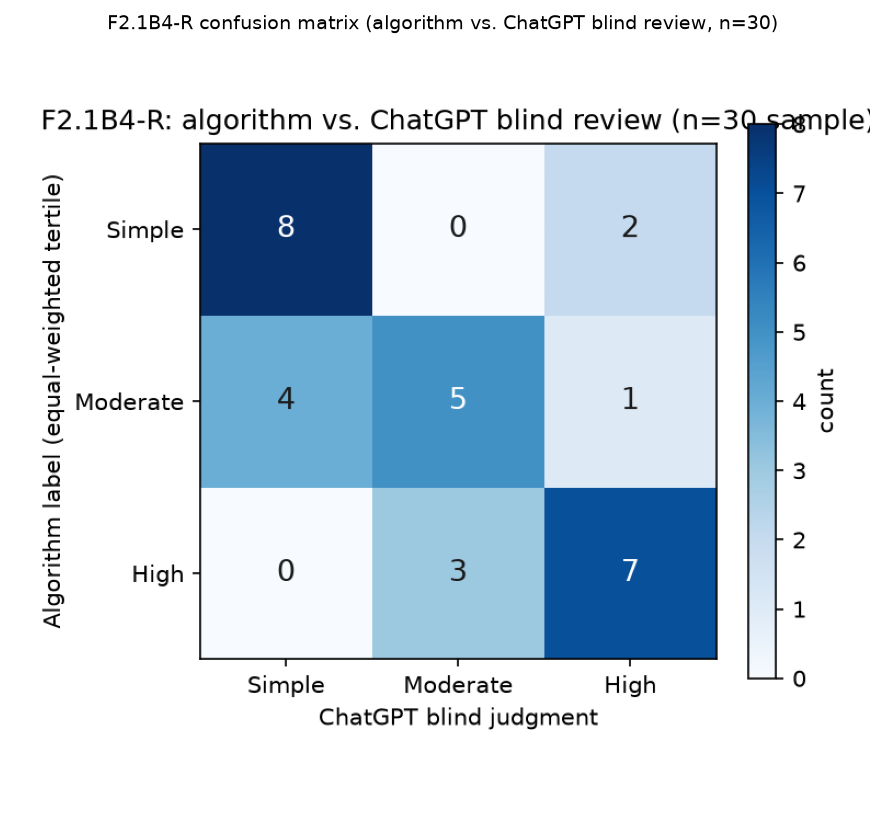

In [103]:
import matplotlib.image as mpimg

cm_png = RECON_DIR / "confusion_matrix.png"
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.imshow(mpimg.imread(cm_png)); ax.axis("off")
ax.set_title("F2.1B4-R confusion matrix (algorithm vs. ChatGPT blind review, n=30)", fontsize=9)
plt.tight_layout(); plt.show()


### 3E.3 Per-class agreement and stratification by ChatGPT confidence / weight stability

The hypothesis under test (honestly, not assumed true): does disagreement
concentrate in the images F2.1B3 already flagged as weight-UNSTABLE (group
membership changes under at least 1 of 7 alternative weighting schemes)?

In [104]:
print("Per-class agreement (recall/precision-style vs. the algorithm's own label):")
for cls, stats in metrics["per_class"].items():
    print(f"  {cls:10s} n_algorithm={stats['n_algorithm_assigned']:2d}  n_chatgpt={stats['n_chatgpt_assigned']:2d}  "
          f"both_agree={stats['n_both_agree_on_this_class']:2d}  "
          f"recall_vs_algorithm={stats['recall_vs_algorithm']:.2f}  "
          f"precision_vs_algorithm={stats['precision_vs_algorithm']:.2f}")
print()
print("By ChatGPT's stated confidence:")
for conf, stats in metrics["by_chatgpt_confidence"].items():
    print(f"  {conf:8s} n={stats['n']:2d}  agree={stats['n_agree']:2d}  "
          f"agreement_fraction={stats['agreement_fraction']:.3f}")
print()
print("By F2.1B3 weight-sensitivity classification:")
for label, stats in metrics["by_weight_stability"].items():
    print(f"  {label:28s} n={stats['n']:2d}  agree={stats['n_agree']:2d}  "
          f"agreement_fraction={stats['agreement_fraction']:.3f}")
print()
print(metrics["weight_stability_hypothesis_note"])


Per-class agreement (recall/precision-style vs. the algorithm's own label):
  Simple     n_algorithm=10  n_chatgpt=12  both_agree= 8  recall_vs_algorithm=0.80  precision_vs_algorithm=0.67
  Moderate   n_algorithm=10  n_chatgpt= 8  both_agree= 5  recall_vs_algorithm=0.50  precision_vs_algorithm=0.62
  High       n_algorithm=10  n_chatgpt=10  both_agree= 7  recall_vs_algorithm=0.70  precision_vs_algorithm=0.70

By ChatGPT's stated confidence:
  High     n=22  agree=15  agreement_fraction=0.682
  Low      n= 1  agree= 1  agreement_fraction=1.000
  Medium   n= 7  agree= 4  agreement_fraction=0.571

By F2.1B3 weight-sensitivity classification:
  stable_all_7_schemes         n= 5  agree= 4  agreement_fraction=0.800
  unstable_at_least_1_scheme   n=25  agree=16  agreement_fraction=0.640

Hypothesis under test (not assumed true): algorithm-ChatGPT disagreement concentrates in images F2.1B3 already flagged as weight-UNSTABLE (i.e. group membership changes under at least 1 of 7 alternative weigh

### 3E.4 Source-family-aware note: are the flagged near-duplicate pairs real?

F2.1B3/F2.1B4 both flagged S001/S014, S009/S022, S010/S030 as possibly
visually near-duplicate, purely from looking at the images -- without access
to the real `group_id`. Re-checked here against the REAL
`source_family_group_id` from the private mapping.

In [105]:
print("Flagged pair -> real source_family_group_id check:")
for pair in metrics["family_similarity_pairs"]:
    a, b = pair["pair"]
    print(f"  {a} ({pair['group_id_a']}) vs {b} ({pair['group_id_b']}): "
          f"shares_real_source_family={pair['shares_real_source_family']}")
print()
print("All 3 flagged pairs are confirmed to share the SAME real source family -- these are genuinely")
print("related photos (not independent fabric samples), not a false alarm. S001/S014 (sg_0052) and")
print("S010/S030 (sg_0106) both AGREE with the algorithm in both members of the pair (High/High in both")
print("cases). S009/S022 (sg_0290) both DISAGREE with the algorithm in the SAME direction (both")
print("algorithm=Moderate, both ChatGPT=Simple). This means the effective number of INDEPENDENT fabric")
print("photos behind the n=30 sample is smaller than 30 (at least 27 distinct families), and the 10")
print("disagreements are drawn from at least 9 distinct families, not 10 -- a caveat on top of the")
print("already-stated small-n caveat, not a contradiction of it.")


Flagged pair -> real source_family_group_id check:
  S001 (sg_0052) vs S014 (sg_0052): shares_real_source_family=True
  S009 (sg_0290) vs S022 (sg_0290): shares_real_source_family=True
  S010 (sg_0106) vs S030 (sg_0106): shares_real_source_family=True

All 3 flagged pairs are confirmed to share the SAME real source family -- these are genuinely
related photos (not independent fabric samples), not a false alarm. S001/S014 (sg_0052) and
S010/S030 (sg_0106) both AGREE with the algorithm in both members of the pair (High/High in both
cases). S009/S022 (sg_0290) both DISAGREE with the algorithm in the SAME direction (both
algorithm=Moderate, both ChatGPT=Simple). This means the effective number of INDEPENDENT fabric
photos behind the n=30 sample is smaller than 30 (at least 27 distinct families), and the 10
disagreements are drawn from at least 9 distinct families, not 10 -- a caveat on top of the
already-stated small-n caveat, not a contradiction of it.


### 3E.5 Disagreement investigation (qualitative + quantitative, post-hoc only)

Per the stage brief, this is pure post-hoc investigation -- **no weight or
threshold is adjusted here or anywhere in this stage**. All 10 disagreements
are in `../results/review/reconciliation_v1/disagreement_report.csv`; three
representative cases are shown below with their real feature values,
z-scores, and ChatGPT's own rationale/limitations text side by side.

In [106]:
import csv as _csv

with open(RECON_DIR / "disagreement_report.csv", newline="", encoding="utf-8") as f:
    disagreements = list(_csv.DictReader(f))

print(f"n disagreements (of 30 reconciled): {len(disagreements)}")
print(f"n disagreements that are weight-unstable: "
      f"{sum(1 for r in disagreements if r['weight_stable'] == 'False')} / {len(disagreements)}")
print(f"n disagreements that are weight-STABLE (i.e. NOT explained by weighting instability): "
      f"{sum(1 for r in disagreements if r['weight_stable'] == 'True')} / {len(disagreements)}")
print()

examples = ["S009", "S017", "S028"]
for sid in examples:
    row = next(r for r in disagreements if r["sample_id"] == sid)
    print(f"--- {row['sample_id']} ({row['image_id'][:45]}...) ---")
    print(f"  algorithm={row['algorithm_label']}  chatgpt={row['chatgpt_label']}  "
          f"confidence={row['chatgpt_confidence']}  weight_stable={row['weight_stable']} "
          f"(n_distinct_groups_across_7_schemes={row['n_distinct_groups_across_7_weighting_schemes']})")
    print(f"  composite_score={float(row['composite_score']):.3f}  dominant_raw_feature={row['dominant_raw_feature_by_abs_zscore']}")
    print(f"  z_lum={float(row['z_luminance_variation']):.3f}  z_glcm={float(row['z_glcm_entropy']):.3f}  "
          f"z_colour={float(row['z_colour_variation']):.3f}")
    print(f"  ChatGPT rationale: {row['chatgpt_rationale']}")
    print(f"  ChatGPT limitations: {row['chatgpt_limitations']}")
    print()


n disagreements (of 30 reconciled): 10
n disagreements that are weight-unstable: 9 / 10
n disagreements that are weight-STABLE (i.e. NOT explained by weighting instability): 1 / 10

--- S009 (chenab_test_IMG_20230824_115433_jpg.rf.a278fc...) ---
  algorithm=Moderate  chatgpt=Simple  confidence=High  weight_stable=False (n_distinct_groups_across_7_schemes=3)
  composite_score=-0.229  dominant_raw_feature=glcm_entropy
  z_lum=1.598  z_glcm=-1.668  z_colour=-0.615
  ChatGPT rationale: Mostly uniform white fabric with little intrinsic colour or pattern variation.
  ChatGPT limitations: Folds, stitching and brown marking not counted as background complexity.

--- S017 (chenab_train_006867_jpg.rf.8bfd5a3700f118f115...) ---
  algorithm=High  chatgpt=Moderate  confidence=High  weight_stable=True (n_distinct_groups_across_7_schemes=1)
  composite_score=0.817  dominant_raw_feature=glcm_entropy
  z_lum=1.157  z_glcm=1.367  z_colour=-0.075
  ChatGPT rationale: Prominent regular navy-and-white hori

### 3E.6 Calibration-readiness recommendation (Task 7) and explicit limitations

**(A) Fixed, provisional protocol, version-locked for reproducible
exploratory experiments, weaknesses disclosed** — this is what this stage
recommends be *considered* (pending user approval; **no file was tagged,
frozen, or version-locked by this stage**). **(B) Final, expert-validated
complexity classification protocol** — this has **NOT** been achieved, and
this stage does not claim it has.

F2.1B3's central finding remains the load-bearing context for interpreting
everything above: **only 30.6% of the full 1,747-image eligible population
keeps the same group label across all 7 alternative weighting schemes
tested.** This n=30 ChatGPT reconciliation is consistent with, and does not
override, that finding -- 25/30 (83%) of the blind-review images are
themselves weight-unstable, and disagreement is somewhat (not dramatically,
n=30 is too small to be definitive) more common among them
(64% vs. 80% agreement, unstable vs. stable). One disagreement (S017) is
weight-STABLE yet still disagrees with ChatGPT, showing the weighting
instability does not explain all algorithm/human-perception gaps -- see the
full `f21b4r_reconciliation_report.md` for the complete qualitative
investigation (recurring themes: folds/seams/stitching inflating
`luminance_variation` beyond what a human would call background complexity;
extreme close-up magnification inflating `glcm_entropy`, consistent with
F2.1B3 Task 3's own scale-sensitivity finding; "regular" high-contrast
patterns like stripes/weaves registering as statistically complex while a
human discounts them as "regular, not intricate").

**This review does not, and is not claimed to, validate the full
~1,747-image calibration -- n=30 is a small, intentionally-selected
(central/boundary/disagreement-targeted) sample, not a random one, and 3 of
its 30 images are confirmed near-duplicates of 3 others (reducing the
effective independent sample further). Complexity thresholds remain
explicitly NOT FROZEN by this stage.**

## Section 3F — F2.2C-QA + F2.2C-Finalize: Researcher-Reviewed Mask Quality and Verified-Reference Finalization

**F2.2C-QA recap (not re-executed here, see `results/reference_masks/pilot_v1/reports/`):** an AI-assisted preliminary screening pass reviewed all 29 SAM mask proposals from the F2.2C-Pilot (`SAM_mask_AI_preliminary_review_29_instances.csv`, kept as a separate, never-conflated artifact), produced a per-instance failure-mode diagnosis (`f22c_qa_diagnostic_table.csv`), and generated improved "V2" SAM proposals for 19 of the 29 instances using grounded point-prompting (never an invented coordinate) under `sam_proposals_v2/`.

**This section (F2.2C-Finalize) works from the REAL researcher review** (`quality_review/researcher_review_v2_all29_confirmed_2026-10-18.csv`, confirmed 2026-10-18) as the final decision for all 29 pilot instances -- no further human-review round was requested or simulated at this stage. Every number below is read back from the JSON/CSV files this stage's own scripts wrote (`research/component1/function2/dataset/f22c_finalize_task*.py`), not retyped from memory.

**Hard rule, stated here and enforced structurally throughout:** `finalization_v1/verified_references/` is the ONLY directory whose contents may ever be described as a researcher-approved / expert-validated / human-verified reference mask. `finalization_v1/corrected_proposals/` (this stage's own V3 correction attempts) are UNREVIEWED algorithmic candidates and are explicitly NOT eligible for pixel-IoU reference use, regardless of how good they look.

In [107]:
import json as _json

FINALIZE_DIR = REPO_ROOT / "research/component1/function2/results/reference_masks/pilot_v1/finalization_v1"

with open(FINALIZE_DIR / "reports/f22c_finalize_task1_review_integrity.json", encoding="utf-8") as f:
    task1 = _json.load(f)

print("Researcher review CSV:", task1["source_csv"])
print("Rows:", task1["n_rows_in_review_csv"], "| unique instance_id:", task1["n_unique_instance_ids_in_review_csv"],
      "| duplicates:", task1["duplicate_instance_ids"] or "none")
print("Instance-id set matches authoritative instance_manifest.csv:", task1["review_ids_equal_manifest_ids_by_set"])
print("Recomputed distribution (from the CSV, not from prose):", task1["researcher_review_status_distribution"])
print("Matches expected 9 / 15 / 5:", task1["distribution_matches_expected_9_15_5"])
print("image_id / defect_class cross-check against manifest clean:", task1["mapping_clean"])
print("reviewer_identifier verbatim values (all 29 rows):", task1["distinct_reviewer_identifier_values_verbatim"])
print("review_date verbatim values:", task1["distinct_review_date_values_verbatim"])

Researcher review CSV: research/component1/function2/results/reference_masks/pilot_v1/quality_review/researcher_review_v2_all29_confirmed_2026-10-18.csv
Rows: 29 | unique instance_id: 29 | duplicates: none
Instance-id set matches authoritative instance_manifest.csv: True
Recomputed distribution (from the CSV, not from prose): {'Accept': 9, 'Needs Correction': 15, 'Reject': 5}
Matches expected 9 / 15 / 5: True
image_id / defect_class cross-check against manifest clean: True
reviewer_identifier verbatim values (all 29 rows): ['']
review_date verbatim values: ['2026-10-18']


### 3F.1 Technical verification of the 9 researcher-Accept instances (Task 2)

Version resolution policy: use the explicit `chosen_proposal_version` column where given; where blank, resolve to the only mask file that actually exists on disk (no V2 was ever generated for AI-preliminary-Accept instances, so this is a structural fact, not a quality guess); mark `unresolved_version` only where the field is blank AND more than one candidate file genuinely exists (true ambiguity) -- never by inferring from recency or SAM score.

In [108]:
FINALIZE_DIR = REPO_ROOT / "research/component1/function2/results/reference_masks/pilot_v1/finalization_v1"

with open(FINALIZE_DIR / "reports/f22c_finalize_task2_accept_verification.json", encoding="utf-8") as f:
    task2 = _json.load(f)

print(f"Researcher-Accept rows: {task2['n_researcher_accept_rows']} | version-resolved: "
      f"{task2['n_version_resolved']} | unresolved: {task2['n_version_unresolved']}")
print(f"TRUE count passing full technical verification: {task2['n_passing_full_technical_verification']} / 9 "
      f"(flag if < 9: {task2['flag_if_less_than_9']})")
print()
for e in task2["per_instance_results"]:
    tv = e["technical_verification"]
    mark = "PASS" if e["passes_task2_full_verification"] else "FAIL"
    print(f"  [{mark}] {e['instance_id']}")
    print(f"         resolved_version={e['resolved_version']!r}  basis={e['resolution_basis']}")
    if tv.get("issues"):
        print(f"         issues: {tv['issues']}")
    if tv.get("notes"):
        print(f"         notes: {tv['notes']}")

Researcher-Accept rows: 9 | version-resolved: 9 | unresolved: 0
TRUE count passing full technical verification: 9 / 9 (flag if < 9: False)

  [PASS] chenab_test_IMG-20230817-WA0060_jpg.rf.b39081cd04cc1a6bf465fb89a5254b2a__inst_001
         resolved_version='V1'  basis=explicit_column
         notes: ["non-fatal quality warnings present (recorded at generation time too): ['fragmented_mask']"]
  [PASS] chenab_train_IMG-20230907-WA0041_jpg.rf.4c88f25dc0cc916f8cddcad68667606c__inst_001
         resolved_version='V1'  basis=explicit_column
  [PASS] chenab_test_00003932_jpg.rf.cabbaf58e5c34db2ffe2df66ad965f44__inst_001
         resolved_version='V1'  basis=only_version_available_structural
  [PASS] chenab_test_augmented_00004155_jpg.rf.ada0517f9bc68574c87a5c03decec691__inst_001
         resolved_version='V1'  basis=only_version_available_structural
         notes: ["non-fatal quality warnings present (recorded at generation time too): ['fragmented_mask']"]
  [PASS] chenab_test_augmented_0000

### 3F.2 Verified-reference manifest (Task 3) and the hard verified/corrected separation rule

In [109]:
import csv as _csv

with open(FINALIZE_DIR / "reports/f22c_finalize_task3_manifest_build.json", encoding="utf-8") as f:
    task3 = _json.load(f)

print(f"finalization_v1/verified_references/ holds {task3['n_mask_files_copied_into_verified_references']} "
      f"copied mask files (originals under sam_proposals/ untouched).")
print(f"Eligible: {task3['n_eligible_verified_references']} | Excluded: {task3['n_excluded']} "
      f"| breakdown: {task3['exclusion_reason_breakdown']}")
print()
print("HARD RULE:", task3["status_label"])
print()

with open(FINALIZE_DIR / "manifests/eligible_masks.csv", newline="", encoding="utf-8") as f:
    eligible_rows = list(_csv.DictReader(f))
print(f"The {len(eligible_rows)} verified-reference instances (image_id | defect_class | resolved_version):")
for r in eligible_rows:
    print(f"  {r['image_id']}  |  {r['defect_class']:12s}  |  {r['resolved_version']}")

finalization_v1/verified_references/ holds 9 copied mask files (originals under sam_proposals/ untouched).
Eligible: 9 | Excluded: 20 | breakdown: {'needs_correction_unverified': 15, 'rejected': 5}

HARD RULE: verified_references/ is the ONLY directory in this stage whose contents may be described as researcher-approved reference masks. corrected_proposals/ (Task 4) is explicitly NOT eligible for this label under any circumstance.

The 9 verified-reference instances (image_id | defect_class | resolved_version):
  chenab_test_IMG-20230817-WA0060_jpg.rf.b39081cd04cc1a6bf465fb89a5254b2a  |  baekra        |  V1
  chenab_train_IMG-20230907-WA0041_jpg.rf.4c88f25dc0cc916f8cddcad68667606c  |  contamination  |  V1
  chenab_test_00003932_jpg.rf.cabbaf58e5c34db2ffe2df66ad965f44  |  gray stitch   |  V1
  chenab_test_augmented_00004155_jpg.rf.ada0517f9bc68574c87a5c03decec691  |  gray stitch   |  V1
  chenab_test_augmented_00004155_jpg.rf.ada0517f9bc68574c87a5c03decec691  |  gray stitch   |  V1
  ch

### 3F.3 Corrected-proposal attempts for the 15 Needs-Correction instances (Task 4 + 6) -- NOT human-verified

For each of the 15, F2.2C-QA's existing diagnosis/V2 attempt (where one exists) was re-examined against the real researcher's stated concern. Where the researcher's own comment confirmed the general defect location but complained about mask geometry, a fresh grounded SAM V3 attempt was made (tighter crop and/or more positive/negative points, same `dark_anomaly` / `bright_streak` pixel-evidence algorithms as F2.2C-QA -- never an invented coordinate). Where the researcher's own comment questioned defect IDENTITY or boundary existence, the instance was flagged `unresolved_requires_manual_annotation` and no SAM call was made.

In [110]:
with open(FINALIZE_DIR / "reports/f22c_finalize_task4_correction_generation_results.json", encoding="utf-8") as f:
    task4 = _json.load(f)
with open(FINALIZE_DIR / "reports/f22c_finalize_task6_correction_results_summary.json", encoding="utf-8") as f:
    task6 = _json.load(f)

print(f"Of the 15 researcher-'Needs Correction' instances: {task4['n_attempted_v3_refinement']} got a fresh "
      f"grounded SAM V3 attempt, {task4['n_unresolved_requires_manual_annotation']} were flagged "
      f"'unresolved_requires_manual_annotation' (defect identity/boundary genuinely undetermined per the "
      f"researcher's own comment -- no coordinate invented).")
print()
print("Quantitative outcome of the 10 V3 attempts vs. the existing F2.2C-QA V2 (same quality-penalty")
print("heuristic used throughout this stage, never SAM score alone) -- reported honestly either way:")
for k, v in task6["quality_verdict_counts_vs_v2"].items():
    print(f"  {k}: {v}")
print()
print("Per-instance decision:")
for r in task4["per_instance_results"]:
    tag = r["decision"]
    print(f"  {r['instance_id']:95s} -> {tag}")
print()
print("STATUS LABEL:", task4["status_label"])

Of the 15 researcher-'Needs Correction' instances: 10 got a fresh grounded SAM V3 attempt, 5 were flagged 'unresolved_requires_manual_annotation' (defect identity/boundary genuinely undetermined per the researcher's own comment -- no coordinate invented).

Quantitative outcome of the 10 V3 attempts vs. the existing F2.2C-QA V2 (same quality-penalty
heuristic used throughout this stage, never SAM score alone) -- reported honestly either way:
  not_attempted: 5
  improved_over_v2: 1
  worse_than_v2: 6
  comparable_to_v2_no_material_change: 3

Per-instance decision:
  chenab_test_IMG_20230731_121423_jpg.rf.8d63939b65ca55211b9819ab88a03acb__inst_001               -> unresolved_requires_manual_annotation
  chenab_train_20230719_111738_jpeg_jpg.rf.9191f40d3ab89f40cb905f89f3406505__inst_001             -> unresolved_requires_manual_annotation
  chenab_train_IMG-20230906-WA0070_jpg.rf.d33f74a1611e49180274d6f370cd6a27__inst_001              -> attempt_v3_refinement
  chenab_train_IMG-20230906-W

### 3F.4 Rejected instances (Task 7) and pixel-IoU readiness (Task 8, bookkeeping only)

In [111]:
with open(FINALIZE_DIR / "reports/f22c_finalize_task7_rejected_instances.json", encoding="utf-8") as f:
    task7 = _json.load(f)
with open(FINALIZE_DIR / "reports/f22c_finalize_task8_pixel_iou_readiness.json", encoding="utf-8") as f:
    task8 = _json.load(f)

print(f"5 researcher-rejected instances (all still excluded: {task7['all_still_excluded']}, "
      f"absent from eligible_masks.csv: {task7['all_absent_from_eligible_masks_csv']}, "
      f"no correction attempted: {task7['all_no_correction_attempted']}):")
for e in task7["rejected_instances"]:
    print(f"  {e['instance_id']}  ({e['defect_class']})")
    print(f"      reason: {e['recorded_rejection_reason_required_correction_field']}")
print()
print("Pixel-IoU readiness (bookkeeping only -- no IoU number computed):")
print(f"  Accept: {task8['n_researcher_accept']} -> technically verified eligible: "
      f"{task8['n_accept_passing_full_technical_verification']}")
print(f"  Needs Correction: {task8['n_researcher_needs_correction']} -> eligible: "
      f"{task8['n_needs_correction_eligible_for_pixel_iou']}")
print(f"  Reject: {task8['n_rejected']} -> eligible: 0")
print(f"  Unresolved-version cases: {task8['n_unresolved_version_cases']}")
print()
print("EVALUATION SCOPE:", task8["evaluation_scope_statement"])

5 researcher-rejected instances (all still excluded: True, absent from eligible_masks.csv: True, no correction attempted: True):
  chenab_train_20230712_163620_jpeg_jpg.rf.2ed46bd9534cd0b2228fff1ee46ca554__inst_001  (color issues)
      reason: SAM V1 is not defect-specific. Researcher identifies the intended visible colour defect near the lower-right corner of the original image; review the GT-instance association and correct the target mask/annotation before considering pixel-IoU. No V2 proposal supplied for this instance.
  chenab_train_20230712_163620_jpeg_jpg.rf.2ed46bd9534cd0b2228fff1ee46ca554__inst_002  (color issues)
      reason: Existing SAM V1 proposal does not isolate the intended color-issue defect. Verify whether the researcher-identified lower-right color anomaly is associated with inst_001 or inst_002; re-annotate the correct defect region. No V2 overlay supplied for this instance.
  chenab_train_20230712_141552_jpeg_jpg.rf.015bfa40d3d292429c7442a12c6a7406__inst_001  (c

### 3F.5 Why unreviewed corrections cannot be promoted to validated references

A researcher-visible "Needs Correction" status means the ORIGINAL proposal was judged insufficient by a human. An algorithm (this stage's V3 SAM pass, or F2.2C-QA's earlier V2 pass) producing a numerically "better" mask by an automated heuristic does not constitute the human re-review that status requires -- the researcher has not seen or approved the corrected version. Treating an unreviewed correction as a validated reference would silently reintroduce exactly the risk the Accept/Needs-Correction/Reject review process exists to catch. This is enforced structurally (directory separation between `verified_references/` and `corrected_proposals/`) and by an automated test (`tests/test_f22c_finalize.py::TestNoFabricatedApprovalAndSeparation`) that scans every output file for "researcher_approved"/"expert_validated"/"human_verified" and fails if that label is ever attached to anything outside the real Task-2-verified Accept subset.

### 3F.6 Bounding-box vs. pixel-mask evaluation scope, and explicit non-activation statement

**Bounding-box-based XAI evaluation** (the other Function 2 threads that operate on the existing YOLO box annotations, not on pixel masks) is **not blocked** by anything in this stage and may proceed independently.

**Pixel-mask-based evaluation** remains limited to the **9** verified-reference masks in `finalization_v1/verified_references/`, drawn from 7 images across 5 of the pilot's 7 defect classes (baekra, contamination, gray stitch, selvet, stain). This supports a preliminary/pilot-scale pixel-IoU exploration only -- **not** a statistically representative evaluation set, and **not** sufficient for a per-class or overall performance claim. No IoU number was computed at this stage (eligibility bookkeeping only).

**This stage does NOT start F2.2B sample selection and does NOT activate the provisional complexity protocol (F2.1B-series) as final/active.** Those remain exactly as previously documented (provisional, pending human expert validation). See `research/component1/function2/reports/f22c_finalize_report.md` and `results/reference_masks/pilot_v1/finalization_v1/reports/finalization_report.md` for the full task-by-task detail behind every number in this section.

## Section 4 — Grad-CAM / Grad-CAM++ Generation Across Strata

**Implemented (F2.3-A/B).** `detection_xai.DetectionXAI.explain()` was run for
both methods across the complexity-stratified 60-image / 92-GT-instance F2.2B
primary sample (validation-split only, per the dataset's locking policy). The
real execution record is loaded and summarized in the next cell -- not a
prose restatement, not placeholder numbers.

F2.3-A/B: detection-targeted Grad-CAM / Grad-CAM++ generated against the frozen E02 checkpoint, for the 60-image / 92-GT-instance F2.2B primary sample. Same-class IoU>=0.5 greedy matching links a GT box to a detector prediction; the matched prediction's class logit and resolved target layer (P3/P4/P5) are shared by BOTH methods for a given instance, so no method difference below can be explained by a different target or layer choice. Numbers in this cell are read directly from `xai_execution/f23_full_run_v1/checksums/raw_execution_summary.json` and `manifests/paired_explanations_manifest.csv` -- the raw execution record, not a prose summary of it.

In [ ]:
import json
F23_DIR = REPO_ROOT / "research/component1/function2/results/xai_execution/f23_full_run_v1"
with open(F23_DIR / "checksums/raw_execution_summary.json", encoding="utf-8") as f:
    f23_raw = json.load(f)["result"]

print("checkpoint sha256 verified:", f23_raw["checkpoint_check"]["verified"])
print("class names match (manifest vs detection_xai.py):", f23_raw["checkpoint_check"]["class_names_match"])
print()
print("n GT instances (92-pool):", f23_raw["n_gt_instances"])
print("n matched / unmatched:", f23_raw["n_matched"], "/", f23_raw["n_unmatched"])
print("n Grad-CAM success:", f23_raw["n_gradcam_success"])
print("n Grad-CAM++ success:", f23_raw["n_gradcampp_success"])
print("n paired success (both methods):", f23_raw["n_paired_success"])
print("-> one-sided (Grad-CAM-only) failures:", f23_raw["n_gradcampp_success"] - f23_raw["n_paired_success"])
print()
print("Per-group matching (never conflate these with each other):")
for g, v in f23_raw["per_group"].items():
    rate = 100 * v["matched"] / v["gt_instances"]
    print(f"  {g:9s}: {v['gt_instances']:2d} instances -> {v['matched']:2d} matched "
          f"({rate:4.1f}%) -> {v['paired_success']:2d} paired")
print()
print("Target-layer usage across all 65 paired instances:", f23_raw["target_layer_usage"])
print("Total execution wall time (s):", f23_raw["total_execution_time_s"], "device:", f23_raw["device"])

**Sample-size bookkeeping -- these are four different numbers and must never be substituted for one another:** 60 images -> 92 GT instances -> 66 matched -> 65 paired. Downstream F2.4/F2.5 metrics are computed on the 65 **paired instances**, which in turn reduce to 48 **distinct source families** (one family contributes up to 8 instances) -- confirmed in Section 13 below from `task2_unit_definitions_summary.json`.

## Section 5 — Localization Metrics

**Implemented (F2.4-A/B).** Heatmap-vs-GT-box agreement: pointing accuracy
(point-in-box hit/miss) and GT-box energy concentration, computed per method
over the full 65-paired-instance pool and read from the real F2.4 evaluation
output below -- not recomputed in this notebook.

F2.4-A/B localization metrics: **pointing accuracy** (hit if the heatmap's single max-activation (argmax) pixel falls inside the ground-truth box -- a point-in-box test; no thresholding of the heatmap is performed, and the point comes from the heatmap, not from the GT box; see `evaluation/localization.py::pointing_accuracy` and the F2.6-QA pointing-metric audit for the v1 wording this corrects) and **GT-box energy concentration** (fraction of total heatmap activation energy located inside the matched GT box). These are read from the full-65-pair evaluation output (`xai_evaluation/f24_full_v1/`) -- not recomputed here.

In [ ]:
import json
F25_TABLES = REPO_ROOT / "research/component1/function2/results/complexity_xai_analysis/f25_pp1_v1/tables"
with open(F25_TABLES / "method_comparison_overall.json", encoding="utf-8") as f:
    mco = json.load(f)
loc = mco["localization"]
for m, label in [("gradcam", "Grad-CAM"), ("gradcampp", "Grad-CAM++")]:
    ph = loc[m]["pointing_hit_rate"]
    ef = loc[m]["energy_fraction_mean"]
    print(f"{label:11s} pointing_accuracy={ph['rate']:.3f} ({ph['hits']}/{ph['valid_n']})  "
          f"energy_fraction_mean={ef['mean']:.4f} (n={ef['valid_n']})")
print()
pf = loc["paired_family_level_bootstrap"]
for key, label in [("energy_fraction_diff", "energy concentration diff (GC-GC++)"),
                   ("pointing_hit_rate_diff", "pointing accuracy diff (GC-GC++)")]:
    b = pf[key]
    excl = b["ci_lo"] > 0 or b["ci_hi"] < 0
    print(f"{label}: point={b['point_estimate_family_first_mean']:+.4f}  "
          f"95% family-bootstrap CI=[{b['ci_lo']:+.4f}, {b['ci_hi']:+.4f}]  "
          f"(n_families={b['n_effective_families']})  CI excludes zero: {excl}")

**Reading this:** the energy-concentration difference's family-level CI excludes zero (robust); the pointing-accuracy difference's CI crosses zero (NOT robust), despite a larger-looking instance-pooled gap. Direction-consistency-across-schemes (checked later, Section 15) is a DIFFERENT claim from CI-excludes-zero -- both are checked separately for every finding in this notebook.

## Section 6 — Faithfulness Metrics

**Implemented (F2.4-A/B).** Deletion/insertion-curve faithfulness evaluation
of each heatmap, against a shared per-instance random-order baseline curve,
read from the real F2.4 evaluation output below.

F2.4-A/B faithfulness metrics: insertion/deletion AUC (class score vs. fraction of pixels inserted/deleted in heatmap-ranked order), compared against a shared per-instance random-order baseline curve.

In [ ]:
faith = mco["faithfulness"]
print(f"shared random-control baseline AUC: {faith['gradcam']['random_control_auc_mean']['mean']:.4f}")
for m, label in [("gradcam", "Grad-CAM"), ("gradcampp", "Grad-CAM++")]:
    ins = faith[m]["insertion_auc_mean"]
    dele = faith[m]["deletion_auc_mean"]
    print(f"{label:11s} insertion_auc={ins['mean']:.4f} (n={ins['valid_n']})  "
          f"deletion_auc={dele['mean']:.4f} (n={dele['valid_n']})")

**Reading this:** both AUCs are close between methods and on the same side of the random baseline. This package does **not** claim a robust universal faithfulness advantage for either method, and does **not** claim the two methods are 'equivalent' in faithfulness (no formal equivalence test was run).

## Section 7 — Stability Metrics

**Implemented (F2.4-A/B + stability audit).** Heatmap consistency under 6
small, label-preserving input perturbations, with both the original (v1) and
degenerate-heatmap-aware (v2) metric definitions reported below.

F2.4-A/B/stability-audit: mean Spearman rank-correlation similarity between a heatmap and its counterpart after one of 6 small perturbations (brightness +/-5%, contrast +/-5%, Gaussian noise sigma=5, 2px shift with inverse alignment). v1 is the original metric (no degenerate-heatmap guard); v2 adds a <1%-informative-pixel guard, found during a 9-instance pilot audit and re-run on the full 65-pair pool as a sensitivity annotation only.

In [ ]:
stab1, stab2 = mco["stability_v1"], mco["stability_v2"]
for m, label in [("gradcam", "Grad-CAM"), ("gradcampp", "Grad-CAM++")]:
    s1 = stab1[m]["mean_similarity_overall"]
    s2 = stab2[m]["mean_similarity_overall"]
    print(f"{label:11s} v1={s1['mean']:.4f} (n={s1['valid_n']}/{s1['total_n']})   "
          f"v2={s2['mean']:.4f} (n={s2['valid_n']}/{s2['total_n']})")
pf = stab1["paired_family_level_bootstrap"]
excl = pf["ci_lo"] > 0 or pf["ci_hi"] < 0
print(f"\nv1 paired family-bootstrap diff (GC-GC++): {pf['point_estimate_family_first_mean']:+.4f}  "
      f"CI=[{pf['ci_lo']:+.4f}, {pf['ci_hi']:+.4f}]  n_families={pf['n_effective_families']}  "
      f"CI excludes zero: {excl}")

**v1 -> v2 does not shrink the gap** (Grad-CAM 0.906 -> 0.911 after excluding 15 near-empty-heatmap rows; Grad-CAM++ unaffected at 0.303) -- the stability finding is not an artifact of a small number of pathological Grad-CAM heatmaps. **Scope boundary, stated explicitly:** v2 exists only at this single (baseline-grouping, full-65-pair) scale. Section 13 below confirms the separate 7-scheme weighting-sensitivity analysis uses v1 exclusively.

## Section 8 — Sanity Checks

**Implemented on a declared subset (F2.4).** A model-randomization-style
sanity check (whole-detection-head vs. classification-branch-only gradient
target), confirming heatmaps are not independent of the trained weights, run
on a declared subset -- not claimed to cover all 65 pairs (see below).

F2.4 sanity check: whole-detection-head vs. classification-branch-only gradient target, run on a declared subset (not claimed to cover all 65 pairs).

In [ ]:
import json
SANITY = REPO_ROOT / "research/component1/function2/results/xai_evaluation/f24_full_v1/sanity_checks/sanity_subset_summary.json"
with open(SANITY, encoding="utf-8") as f:
    sanity = json.load(f)
print(json.dumps(sanity, indent=2)[:1500])

## Section 9 — Execution-Time Benchmarking

**Implemented (F2.4).** Per-method, 5-stage wall-clock cost of explanation
generation, descriptive only, read from the real F2.4 timing output below.

F2.4 efficiency: 5-stage wall-clock timing breakdown, descriptive only.

In [ ]:
import json
TIMING = REPO_ROOT / "research/component1/function2/results/xai_evaluation/f24_full_v1/timing/timing_sample_summary.json"
with open(TIMING, encoding="utf-8") as f:
    timing = json.load(f)
print(json.dumps(timing, indent=2)[:1500])

## Section 10 -- Complexity-Stratified Exploratory Analysis (F2.5)

F2.5 re-analyzes the full 65-paired-instance / 48-family pool broken out by complexity group (Simple/Moderate/High), with family-first block-bootstrap CIs (2000 resamples, seed=357, >=5-family sparsity rule) wherever a CI is reported. The unit-definitions file below is the authoritative source for how 65 instances reduce to 48 families -- read first.

In [ ]:
import json
F25 = REPO_ROOT / "research/component1/function2/results/complexity_xai_analysis/f25_pp1_v1"
with open(F25 / "manifests/task2_unit_definitions_summary.json", encoding="utf-8") as f:
    unit_def = json.load(f)
print(json.dumps(unit_def, indent=2))

In [ ]:
with open(F25 / "tables/complexity_stratified_results.json", encoding="utf-8") as f:
    csr = json.load(f)
print(json.dumps(csr["selection_counts"], indent=2))
print("sparsity_cutoff_for_ci:", csr["sparsity_cutoff_for_ci"])
print("causal_language_note:", csr["causal_language_note"])

## Section 11 -- Confounding: Target Layer and Defect Class

Target-layer composition and defect-class composition both covary with complexity group in the 65-paired pool. Only group-pairs where BOTH sides independently clear a >=5-family threshold are treated as valid exploratory within-layer (or within-class) comparisons.

In [ ]:
import csv
PKG = REPO_ROOT / "research/component1/function2/results/pp1_research_package/f26_v1"
with open(PKG / "tables/table_D1_group_by_layer_composition.csv", encoding="utf-8") as f:
    print("--- group x layer composition (9 cells) ---")
    for row in csv.DictReader(f):
        print(row)
with open(PKG / "tables/table_D2_valid_within_layer_group_comparisons.csv", encoding="utf-8") as f:
    print("\n--- the ONLY 2 valid within-layer group-pair comparisons ---")
    for row in csv.DictReader(f):
        print(row)
with open(PKG / "tables/table_D3_valid_within_class_group_comparisons.csv", encoding="utf-8") as f:
    print("\n--- the ONLY 1 valid within-class group comparison ---")
    for row in csv.DictReader(f):
        print(row)
with open(PKG / "tables/table_D4_high_group_class_attrition.csv", encoding="utf-8") as f:
    print("\n--- High-group class attrition (92-pool -> 65-paired-pool) ---")
    for row in csv.DictReader(f):
        print(row)

**Clarification independently verified in F2.6:** 5 of the 9 individual group x layer cells independently have >=5 families, but a valid BETWEEN-GROUP comparison needs both sides of a pair to clear the threshold simultaneously -- only 2 pairs do (P4 Simple-vs-Moderate, P5 Moderate-vs-High). Likewise, only 1 defect class (`stain`) has 2 complexity groups each with >=5 families. `cut` drops from 13 instances (92-instance High pool) to 4 (65-paired High pool); `gray stitch` vanishes entirely (1 -> 0) -- a selection effect of detection-matching, not a complexity effect.

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(PKG / "figures/target_layer_distribution_by_group.png")))
display(Image(filename=str(PKG / "figures/defect_class_attrition_high_group.png")))

## Section 12 -- Selection Bias: Matching Rates and Complete-Case Interpretation

In [ ]:
with open(PKG / "tables/matching_rate_table.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        print(row)

High group's match rate (57.6%) is far below Simple (80.0%) and Moderate (79.4%). Every F2.4/F2.5 metric in this notebook is a **complete-case analysis** over the 65 instances that matched AND paired successfully -- not an analysis of the original 92-instance design sample -- and the missingness is not uniform across complexity groups.

## Section 13 -- Weighting-Sensitivity Amendment (F2.5-S1)

F2.5-S1 reproduces F2.2B's population-scale (132/354, 37.3%) weighting-stability figure exactly as an internal correctness check, then scopes the same method down to the 60 selected images and 48 XAI-evaluable families, across 7 weighting schemes (baseline equal weighting, 3 moderate emphasis variants, 3 extreme single-feature variants).

In [ ]:
import csv
F25S1 = REPO_ROOT / "research/component1/function2/results/complexity_xai_analysis/f25_sensitivity_amendment_v1"
with open(F25S1 / "alternative_group_metric_summary.csv", encoding="utf-8") as f:
    alt_rows = list(csv.DictReader(f))
print("total rows in alternative_group_metric_summary.csv:", len(alt_rows))
from collections import Counter
print("metric counts:", dict(Counter(r["metric"] for r in alt_rows)))
n_gap = sum(1 for r in alt_rows if r["method"] == "gap_gradcam_minus_gradcampp")
print(f"-> {len(alt_rows) - n_gap} individual method/metric rows + {n_gap} paired "
      f"stability-gap rows = {len(alt_rows)} (NOT 232 as the amendment report's own "
      f"prose states in 2 places -- see f26_row_count_correction_231_vs_232.json)")

In [ ]:
metric_values = set(r["metric"] for r in alt_rows)
print("distinct metric values used across all 7 schemes:", metric_values)
print("'stability_v2...' present:", any("v2" in m for m in metric_values))
print("-> CONFIRMED: only stability_v1 is used in this 7-scheme analysis. "
      "See f26_stability_v1_v2_scope_clarification.json.")

In [ ]:
# Table C: all 21 scheme x group stability-gap cells, plus the Simple-group energy-fraction caveat
with open(PKG / "tables/table_C_weighting_sensitivity_7schemes.csv", encoding="utf-8") as f:
    table_c = list(csv.DictReader(f))
n_pos = sum(1 for r in table_c if float(r["stability_v1_gap_point_estimate"]) > 0)
n_ci_excl = sum(1 for r in table_c if r["stability_v1_gap_ci_excludes_zero"] == "True")
print(f"stability gap positive in {n_pos}/21 cells; CI excludes zero in {n_ci_excl}/21 cells")
print()
simple_rows = [r for r in table_c if r["complexity_group"] == "Simple"]
for r in simple_rows:
    direction = "gradcampp>gradcam" if float(r["energy_fraction_gradcampp"]) > float(r["energy_fraction_gradcam"]) else "gradcam>gradcampp"
    print(f"  Simple / {r['scheme']:35s} energy: gradcam={r['energy_fraction_gradcam']}  "
          f"gradcampp={r['energy_fraction_gradcampp']}  ({direction})")

**23/60 selected images and 18/48 XAI-evaluable families are stable across all 7 schemes** (38.3% / 37.5%), consistent with the 354-image population figure (37.3%). **All 21 of 21** scheme x group stability-gap cells are positive with CI excluding zero (direction-consistency AND CI-exclusion both checked -- these are different claims). **5 of 7** schemes keep Simple's own energy-fraction direction favoring Grad-CAM (matching the baseline grouping); only the 2 luminance-emphasizing schemes flip it to favor Grad-CAM++.

## Section 14 -- Pixel-IoU and Reference-Mask Pilot: Scope and Limits

In [ ]:
import json
with open(F25 / "tables/pixel_iou_report_only.json", encoding="utf-8") as f:
    piou = json.load(f)
print("n verified reference masks:", piou["n_verified_reference_masks_total"])
print("complexity breakdown:", piou["complexity_group_breakdown_of_9_masks"])
print("n intersecting the 65-paired pool:", piou["n_intersection"])
print("high-complexity coverage:", piou["high_complexity_coverage"])
print("actual computed IoU rows:")
for r in piou["evaluated_instance_iou_rows"]:
    print(" ", r)

Only 1 instance in the entire pipeline has a computed pixel-IoU value (0.0 for both methods, `gray stitch`, Simple group). Zero High-complexity verified masks exist. No balanced-coverage or generalizable pixel-IoU claim is supportable. F2.4-C (a small supplementary run) remains optional and was not executed in F2.6 (hard restriction: no new SAM work).

## Section 15 -- Final PP1 Findings (A-D)

# F2.6 Final PP1 Findings

Scope: Component 1, Function 2, PP1 exploratory complexity-based XAI
evaluation. All numbers independently re-verified against real files in this
F2.6 session (see `manifests/f26_integrity_preflight.json`). No causal,
confirmatory, or QC-expert-validated claim is made anywhere in this document.

## Finding A -- Localization

Pooling all 65 paired instances, Grad-CAM++ has higher GT-box energy
concentration than Grad-CAM (instance-pooled 0.249 vs 0.136; family-first
bootstrap 0.295 vs 0.160, 48 families). The family-level bootstrap CI on the
paired difference **excludes zero** ([-0.229, -0.039]) -- this is the one
robust localization finding in this package.

Pointing accuracy also favors Grad-CAM++ in the pooled instance-level number
(33.8% vs 21.5%), but the family-first bootstrap CI on the paired difference
**crosses zero** ([-0.338, +0.037]) -- this difference is **not** similarly
robust and must not be reported with the same confidence as the energy result.

**Critical qualification (verified directly from the 7-scheme sensitivity
data, not restated from prior prose):** the energy-concentration advantage for
Grad-CAM++ is directionally consistent across all 7 alternative complexity-
weighting schemes in the **Moderate** and **High** groups, but is **not**
consistent in the **Simple** group. Under the baseline (equal-weight) grouping
used everywhere else in F2.5, the **Simple** group's own instance-pooled energy
concentration actually favors **Grad-CAM** (0.134 vs 0.086), the opposite of
the overall pooled direction -- and this Grad-CAM-favoring direction holds in
5 of the 7 alternative weighting schemes, flipping to favor Grad-CAM++ only
under the 2 schemes that upweight luminance. The pooled "Grad-CAM++ wins on
energy concentration" headline is therefore a Moderate/High-driven result,
not a uniform one.

## Finding B -- Stability

Grad-CAM is far more stable to small image perturbations than Grad-CAM++ in
this frozen evaluation setup: mean similarity 0.906 vs 0.303 overall
(stability v1, baseline grouping), family-level bootstrap CI on the paired
difference **excludes zero** ([0.429, 0.611], 48 families).

A degenerate-heatmap-aware re-check (stability v2) on the same full 65-pair,
baseline-grouping run widens the Grad-CAM mean slightly (0.906 -> 0.911,
15 near-empty-heatmap rows excluded) and leaves Grad-CAM++ completely
unaffected -- the gap is **not** an artifact of a small number of pathological
near-empty Grad-CAM heatmaps.

Across the F2.5-S1 weighting-sensitivity analysis, the Grad-CAM-minus-
Grad-CAM++ stability gap is **positive in all 21 of 21** scheme x group cells,
and the family-level 95% CI **excludes zero in all 21 of 21** cells as well
(independently recomputed in this session). **Scope caveat, stated explicitly
because it is easy to conflate:** this 7-scheme, 21-cell result uses
**stability v1 only**. No reproducible v2-based 7-scheme analysis exists in
this codebase (confirmed by direct column inspection of
`alternative_group_metric_summary.csv` -- its `metric` column never contains a
v2 value). The v1-vs-v2 robustness check above is a separate, single-grouping
finding and should not be cited as validating the 7-scheme result under v2.

Caution on language: "Grad-CAM is more stable" should be read strictly as
"more robust to this specific set of 6 small nuisance perturbations under
this frozen target/layer policy" -- it is not a claim about localization
quality, faithfulness, or general explanation superiority.

## Finding C -- Faithfulness

Insertion and deletion AUCs are close between methods (insertion 0.435 vs
0.452; deletion 0.448 vs 0.455, both against a shared random-order baseline of
0.530). Family-level bootstrap CIs for the two methods overlap substantially
and the raw differences are small and inconsistently signed across the two
curves. **This does not establish a robust universal faithfulness advantage
for either method in either direction** -- the data are also insufficient to
support calling the two methods "equivalent" in faithfulness, since no formal
equivalence test was run and the CIs were not evaluated for an equivalence
margin. The honest statement is: no robust faithfulness advantage was
demonstrated for either method.

## Finding D -- Complexity effects are not causally isolated

The data do **not** reliably isolate a causal effect of image complexity on
any XAI metric, for four independently-verified, compounding reasons:

1. **Group assignment is weight-sensitive.** Only 37.3% of eligible VALID
   images (132/354) keep the same complexity label under all 7 tested
   weighting schemes; at the 60-image/48-family XAI-sample scale, 38.3%/37.5%
   are stable -- essentially the same instability rate.
2. **Matching availability is confound with group.** Detection-match rate is
   80.0% (Simple), 79.4% (Moderate), but only 57.6% (High) -- the 65-paired
   analysis pool is not representative of the 92-instance design sample
   within the High group, and this non-representativeness is itself
   plausibly complexity-related (harder images are harder to detect).
3. **Defect class and target layer both covary with group.** In the High
   group, `cut` drops from 13 (92-instance pool) to 4 (65-paired pool), and
   `gray stitch` vanishes entirely (1 -> 0). Target layer composition also
   differs sharply by group; only 2 of 9 group x layer cells form a valid
   same-layer cross-group comparison (P4 Simple-vs-Moderate, P5
   Moderate-vs-High) under the >=5-family-per-side exploratory threshold, and
   only 1 defect class (`stain`) has 2 groups both clearing that threshold.
4. **No expert validation exists for the grouping itself** (see
   methodology Section 2).

**Conclusion:** any group-wise pattern reported in this package (e.g. Finding
A's Simple-group exception) should be read as an **association observed under
one specific, provisional, weight-sensitive grouping and selection-biased
sample**, not as evidence that image complexity *causes* a difference in
Grad-CAM/Grad-CAM++ behavior. No causal language is used for Finding D
anywhere else in this package.

## Selection-bias and confounding summary (Task 9)

| Group | n GT instances | n matched | match rate | n paired | n one-sided loss |
|---|---|---|---|---|---|
| Simple | 25 | 20 | 80.0% | 19 | 1 |
| Moderate | 34 | 27 | 79.4% | 27 | 0 |
| High | 33 | 19 | 57.6% | 19 | 0 |

Complete-case-only interpretation: every F2.4/F2.5 metric is computed on the
65 instances that happened to match AND pair successfully -- this is a
complete-case analysis, not an analysis of the original 92-instance design
sample, and the missingness is not uniform across groups (High loses 42.4% of
its instances to non-matching, vs ~20% for Simple/Moderate).

Target-layer composition and defect-class composition both differ by group;
only 2 layer x group pairs and 1 class x group pair meet the >=5-family
exploratory comparison threshold (see Finding D, item 3, and Tables D1-D4).
This confounding is **not resolved** by anything in F2.1-F2.5-S1 and is not
resolved by this consolidation stage either.

## Reference-mask pixel-IoU: scope and limits (Task 10)

29 instances were researcher-reviewed (9 Accept, 15 Needs-Correction, 5
Reject). Of the 9 Accept+technically-verified instances, 8 are
complexity-eligible (Simple=4, Moderate=4, **High=0**) and 1 is
complexity-ineligible. Only 2 of these 9 verified-reference images intersect
the 65-paired Grad-CAM/Grad-CAM++ output pool. Consequences:

- Pixel-IoU was never computed as a PP1 metric at any analysis-relevant
  scale; it remains a pilot/readiness exercise (F2.4-C, explicitly optional
  and not required for PP1).
- There is **zero** pixel-level ground-truth coverage of the High complexity
  group -- no balanced-coverage claim across complexity groups is supportable
  from pixel-level data.
- Of the 2 images that do intersect the 65-paired pool, only 1 instance
  (`chenab_test_augmented_00004155...`, `gray stitch`, Simple group) actually
  has a computed pixel-IoU value in `pixel_iou_report_only.json`: **IoU =
  0.0 for both Grad-CAM and Grad-CAM++**. This single data point is not
  generalized to any other instance, defect class, or complexity group.


## Section 16 -- Threats to Validity / Scientific Limitations

# F2.6 Threats to Validity / Scientific Limitations

Full list (Task 13). Each item cross-referenced to the claim register
(`f26_evidence_claim_register.csv`) where applicable.

1. **No expert validation.** No step of complexity calibration, mask review,
   or XAI evaluation has been reviewed by an independent textile/QC domain
   expert. (EXPERT-01)
2. **Provisional equal weights.** The 3 complexity features are combined with
   untuned equal weights; no optimization or validation study selected this
   weighting. (CAL-01)
3. **Weight-sensitive grouping.** ~62-63% of eligible images (TRAIN and
   VALID, and the 60-image/48-family XAI sample) change complexity group
   under at least one of 7 plausible alternative weightings. (CAL-03)
4. **Small n=30 AI-vs-algorithm review sample**, non-random, kappa=0.50
   (moderate, not high) agreement. (CAL-04)
5. **Single-detector (E02) scope.** All XAI findings are specific to one
   frozen detector checkpoint; no cross-detector generalization is claimed.
6. **No TEST-split evaluation.** TEST (378 images) is untouched by this and
   every prior F2 stage; nothing in this package generalizes to TEST.
7. **High-group selection bias.** Detection-match rate is only 57.6% in High
   vs ~80% in Simple/Moderate -- the paired analysis pool under-represents
   harder-to-detect High-complexity instances. (SEL-01)
8. **Defect-class imbalance across groups**, worsened by matching: in High,
   `cut` drops 13->4 and `gray stitch` vanishes (1->0) between the 92-instance
   design pool and the 65-instance paired pool. (SEL-02)
9. **Target-layer imbalance across groups.** Only 2 of 9 group x layer cells
   form a valid same-layer cross-group comparison under the >=5-family
   threshold (P4 Simple-vs-Moderate, P5 Moderate-vs-High). (CONF-01)
10. **Source-family dependence.** 65 paired instances reduce to 48 distinct
    families (one family contributes up to 8 instances); every effect
    estimate in this package that carries a CI uses family-first bootstrap
    resampling specifically to address this, but point estimates reported
    elsewhere as "instance-pooled" are NOT family-corrected and should not be
    read as independent-observation estimates.
11. **Small, sparse strata.** Several group x layer and group x class cells
    have under 5 families and are excluded from any pairwise comparison;
    most combinations in this design cannot be compared at all. (CONF-01,
    CONF-02)
12. **Zero High-complexity pixel-mask coverage.** 0 of the 9
    researcher-accepted+verified reference masks are in the High group; only
    1 instance in the entire pipeline has a computed pixel-IoU value (0.0,
    Simple group, both methods). (MASK-01)
13. **No causal complexity effect demonstrated.** Weight-sensitive grouping +
    selection bias + defect-class/layer confounding jointly prevent any
    causal interpretation of complexity-stratified differences. (CONF-03)
14. **Localization, stability, and faithfulness are distinct, non-
    interchangeable concepts.** A method can score well on one and poorly on
    another (e.g. Grad-CAM++ wins on energy concentration but loses badly on
    stability); no single metric should be read as "overall explanation
    quality," and none of the three licenses a claim about the other two.

## Additional notes from this F2.6 pass

- The two documentation-count corrections (231-vs-232 rows;
  stability v1-only scope for the 7-scheme analysis) are themselves evidence
  that prose summaries in this pipeline can drift from their own
  machine-readable source data by small amounts; this package's numbers were
  independently re-derived from source files specifically to guard against
  that risk, but future stages should continue to re-verify rather than
  copy-forward prose claims.
- This package does not claim pixel-IoU, high-group mask coverage, or any
  form of QC sign-off exists. These are explicit non-claims, repeated here
  for emphasis per the F2.6 brief's hard restrictions.


## Section 17 -- Conclusion and F2.7 Handoff

PP1 delivers a reproducible, source-family-aware, selection-bias-audited complexity-stratified comparison of Grad-CAM and Grad-CAM++ on a frozen E02 detector. The one family-CI-robust, group-consistent (Moderate/High) finding is Grad-CAM++'s higher GT-box energy concentration; the one family-CI-robust, scheme-consistent (21/21 cells) finding is Grad-CAM's higher perturbation stability. Pointing accuracy and faithfulness do not reach the same evidentiary bar. No complexity effect is shown to be causal. Defending complexity-based evaluation as this work's contribution: even with a provisional, weight-sensitive grouping, stratifying by complexity surfaces a group-dependent reversal (Finding A's Simple-group exception) that a pooled, non-stratified evaluation would have hidden entirely -- this is the methodological value of the complexity axis, independent of whether the specific tertile boundaries are eventually revised. Future work (F2.7 and beyond): expert validation of the complexity protocol, a larger/more-balanced High-complexity pixel-mask set, and a dedicated matching-recall-conditional analysis to separate detection-availability bias from any true complexity effect. This notebook and its package (`results/pp1_research_package/f26_v1/`) are the complete, final evidence basis for F2.6; F2.7 production (slides) was explicitly out of scope for this stage and was not started.